In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. Dataset Spend

## 1.1 Data Loading

In [ ]:
spend = pd.read_excel('/content/drive/MyDrive/Final_Project/Spend (Done).xlsx')
spend.head()

,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
0,2023-07-03,Google Ads,gen_analyst_DE,6,0.00,0,NaN,NaN
1,2023-07-03,Google Ads,performancemax_eng_DE,4,0.01,1,NaN,NaN
2,2023-07-03,Facebook Ads,NaN,0,0.00,0,NaN,NaN
3,2023-07-03,Google Ads,NaN,0,0.00,0,NaN,NaN
4,2023-07-03,CRM,NaN,0,0.00,0,NaN,NaN


## 1.2 Initial Data Inspection

### Dataset Overview

In [ ]:
print("SPEND DATASET SHAPE")
print(spend.shape)

print("\n" + "=" * 80 + "\n")

print("DATASET INFO")
spend.info()

print("\n" + "=" * 80 + "\n")

print("DESCRIPTIVE STATISTICS")
display(spend.describe())

SPEND DATASET SHAPE
(20779, 8)


DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20779 entries, 0 to 20778
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         20779 non-null  datetime64[ns]
 1   Source       20779 non-null  object        
 2   Campaign     14785 non-null  object        
 3   Impressions  20779 non-null  int64         
 4   Spend        20779 non-null  float64       
 5   Clicks       20779 non-null  int64         
 6   AdGroup      13951 non-null  object        
 7   Ad           13951 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 1.3+ MB


DESCRIPTIVE STATISTICS


,Date,Impressions,Spend,Clicks
count,20779,20779.000000,20779.000000,20779.000000
mean,2024-01-14 22:32:40.864334080,2458.203475,7.195892,23.990616
min,2023-07-03 00:00:00,0.000000,0.000000,0.000000
25%,2023-10-13 00:00:00,0.000000,0.000000,0.000000
50%,2024-01-27 00:00:00,63.000000,0.580000,1.000000
75%,2024-04-16 00:00:00,709.000000,5.750000,12.000000
max,2024-06-21 00:00:00,431445.000000,774.000000,2415.000000
std,NaN,11442.528075,26.760080,85.245714


Conclusion:

Impressions, Spend, and Clicks contain values substantially higher than most observations, resulting in means above the corresponding medians. However, such variation can be expected in advertising data, where individual campaigns or activities may generate significantly higher impressions, spending, and clicks. Therefore, the high values are not treated as data errors and are retained.

### Date Conversion

In [ ]:
spend["Date"] = pd.to_datetime(
    spend["Date"],
    errors="raise"
)

print("Date Data Type:", spend["Date"].dtype)

Date Data Type: datetime64[ns]


### Missing Values

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": spend.isna().sum(),
    "Missing Percentage (%)": round(spend.isna().sum() / spend.shape[0] * 100, 2)
})

print("Missing Values\n")
print(missing_values)

Missing Values

             Missing Count  Missing Percentage (%)
Date                     0                    0.00
Source                   0                    0.00
Campaign              5994                   28.85
Impressions              0                    0.00
Spend                    0                    0.00
Clicks                   0                    0.00
AdGroup               6828                   32.86
Ad                    6828                   32.86


#### Missing Values by Source

In [ ]:
print("Missing Values by Source (Count)")

spend.groupby("Source")[["Campaign", "AdGroup", "Ad"]].agg(
    lambda x: x.isna().sum()
)

Missing Values by Source (Count)


,Campaign,AdGroup,Ad
Source,,,
Bloggers,787,787,787
CRM,355,355,355
Facebook Ads,518,518,518
Google Ads,519,1428,1428
Offline,61,61,61
Organic,518,518,518
Partnership,234,234,234
Radio,27,27,27
SMM,614,543,543


In [ ]:
print("Missing Values by Source (%)" + "\n")

missing_by_source = (
    spend.groupby("Source")[["Campaign", "AdGroup", "Ad"]]
    .agg(lambda x: x.isna().mean() * 100)
    .round(2)
)

missing_by_source

Missing Values by Source (%)



,Campaign,AdGroup,Ad
Source,,,
Bloggers,100.00,100.00,100.00
CRM,100.00,100.00,100.00
Facebook Ads,5.32,5.32,5.32
Google Ads,36.34,100.00,100.00
Offline,100.00,100.00,100.00
Organic,100.00,100.00,100.00
Partnership,100.00,100.00,100.00
Radio,100.00,100.00,100.00
SMM,100.00,88.44,88.44


Note:

A source labeled Test was identified among the advertising sources. According to information provided by the business, records associated with this source represent test activity and do not reflect actual business operations. Therefore, these records will be excluded from the dataset to prevent distortions in subsequent analysis.


AdGroup and Ad have the same number of missing values (6,828). We check whether these missing values occur in the same rows.

In [ ]:
print("Missing Values Relationship: AdGroup and Ad")

pd.crosstab(
    spend["AdGroup"].isna(),
    spend["Ad"].isna()
)

Missing Values Relationship: AdGroup and Ad


Ad,False,True
AdGroup,,
False,13951,0
True,0,6828


In [ ]:
print("Missing Value Patterns")

spend[
    ["Campaign", "AdGroup", "Ad"]
].isna().value_counts()

Missing Value Patterns


,,,count
Campaign,AdGroup,Ad,
False,False,False,13874
True,True,True,5917
False,True,True,911
True,False,False,77


Conclusion:

Missing values are found only in Campaign, AdGroup and Ad, and their occurrence depends on the Source. Missing values in AdGroup and Ad always occur together, while Campaign can be missing independently. Sources such as CRM, Organic, Offline, and Bloggers have no recorded advertising hierarchy, whereas paid advertising sources generally provide more detailed information. This suggests that missing values are mainly related to differences in tracking and reporting structures rather than random data loss. Therefore, these values were retained without imputation.

Пропущенные значения встречаются только в Campaign, AdGroup и Ad, а их наличие зависит от Source. Пропуски в  AdGroup и Ad всегда встречаются одновременно, тогда как Campaign может отсутствовать независимо от них. Такие источники, как CRM, Organic, Offline, Bloggers, Partnership, Radio и Telegram posts не содержат информации о рекламной иерархии, тогда как источники платной рекламы обычно предоставляют более подробные данные. Это позволяет предположить, что пропуски преимущественно связаны с различиями в системах отслеживания и отчётности, а не со случайной потерей данных. Поэтому пропуски были сохранены без заполнения.

#### Removing Test Data

In [ ]:
print("Number of Test Records: ", (spend["Source"] == "Test").sum())

Number of Test Records:  262


In [ ]:
spend = spend[
    spend["Source"] != "Test"
].reset_index(drop=True)

In [ ]:
print("Test Records Remaining:",
      (spend["Source"] == "Test").sum()
)

Test Records Remaining: 0


Conclusion:

262 records with Source = "Test" were identified. These records represent test activity rather than real advertising data, so they were removed from the dataset.

### Unique Values

In [ ]:
print("Spend Dataset Shape:", spend.shape)

print("\nNumber of Unique Values")

spend.select_dtypes(include="object").nunique()

Spend Dataset Shape: (20517, 8)

Number of Unique Values


,0
Source,13
Campaign,50
AdGroup,20
Ad,165


## 1.3 Duplicates

In [ ]:
print("Number of Duplicated Rows:", spend.duplicated().sum())
print()

print("Duplicated Rows")

spend[
    spend.duplicated(keep=False)
].sort_values(
    ["Date", "Source", "Campaign", "AdGroup", "Ad"]
)

Number of Duplicated Rows: 917

Duplicated Rows


,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
753,2023-07-23,Bloggers,NaN,0,0.0,0,NaN,NaN
755,2023-07-23,Bloggers,NaN,0,0.0,0,NaN,NaN
768,2023-07-24,Bloggers,NaN,0,0.0,0,NaN,NaN
789,2023-07-24,Bloggers,NaN,0,0.0,0,NaN,NaN
841,2023-07-25,Bloggers,NaN,0,0.0,0,NaN,NaN
...,...,...,...,...,...,...,...,...
20511,2024-06-21,Organic,NaN,0,0.0,0,NaN,NaN
20476,2024-06-21,SMM,NaN,0,0.0,0,NaN,NaN
20488,2024-06-21,SMM,NaN,0,0.0,0,NaN,NaN
20467,2024-06-21,Telegram posts,NaN,0,0.0,0,NaN,NaN


In [ ]:
print("Duplicate Groups")

duplicate_groups = (
    spend[spend.duplicated(keep=False)]
    .value_counts(dropna=False)
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

duplicate_groups

Duplicate Groups


,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad,Count
6,2024-04-01,Telegram posts,NaN,0,0.0,0,NaN,NaN,4
5,2024-04-09,Telegram posts,NaN,0,0.0,0,NaN,NaN,4
4,2024-04-10,Telegram posts,NaN,0,0.0,0,NaN,NaN,4
3,2024-04-05,Telegram posts,NaN,0,0.0,0,NaN,NaN,4
2,2024-04-03,Telegram posts,NaN,0,0.0,0,NaN,NaN,4
...,...,...,...,...,...,...,...,...,...
605,2023-08-05,Bloggers,NaN,0,0.0,0,NaN,NaN,2
604,2023-08-06,Bloggers,NaN,0,0.0,0,NaN,NaN,2
603,2023-09-01,Bloggers,NaN,0,0.0,0,NaN,NaN,2
602,2024-06-17,Facebook Ads,NaN,0,0.0,0,NaN,NaN,2


In [ ]:
duplicated_rows = spend[spend.duplicated(keep=False)]

print("Duplicated Rows Summary")
print("Total:", len(duplicated_rows))
print("Campaign filled:", duplicated_rows["Campaign"].notna().sum())
print("AdGroup filled:", duplicated_rows["AdGroup"].notna().sum())
print("Ad filled:", duplicated_rows["Ad"].notna().sum())
print("Impressions > 0:", (duplicated_rows["Impressions"] > 0).sum())
print("Spend > 0:", (duplicated_rows["Spend"] > 0).sum())
print("Clicks > 0:", (duplicated_rows["Clicks"] > 0).sum())

Duplicated Rows Summary
Total: 1527
Campaign filled: 0
AdGroup filled: 0
Ad filled: 0
Impressions > 0: 0
Spend > 0: 0
Clicks > 0: 14


Conclusion:

917 repeated records were identified across 610 groups, with 1,527 records participating in these groups in total. All participating records have missing Campaign, AdGroup, and Ad values and zero Impressions and Spend; only 14 records have non-zero Clicks.  
These identical records can represent separate observations for the same Date and Source, for example multiple placements within the same source. Therefore, they are considered valid records and are retained.

## 1.4 Categorical Data Analysis

### Source Distribution

In [ ]:
source_distribution = pd.DataFrame({
    "Count": spend["Source"].value_counts(dropna=False),   # сколько раз встречается каждое уник значение + NaN как отдельная категория
    "Percentage (%)": (
        spend["Source"].value_counts(normalize=True, dropna=False) * 100    # при normalize=True возвращает долю от общего количества
    ).round(2)
})

source_distribution

,Count,Percentage (%)
Source,,
Facebook Ads,9732,47.43
Tiktok Ads,3066,14.94
Youtube Ads,1926,9.39
Google Ads,1428,6.96
Telegram posts,1003,4.89
Bloggers,787,3.84
Webinar,766,3.73
SMM,614,2.99
Organic,518,2.52


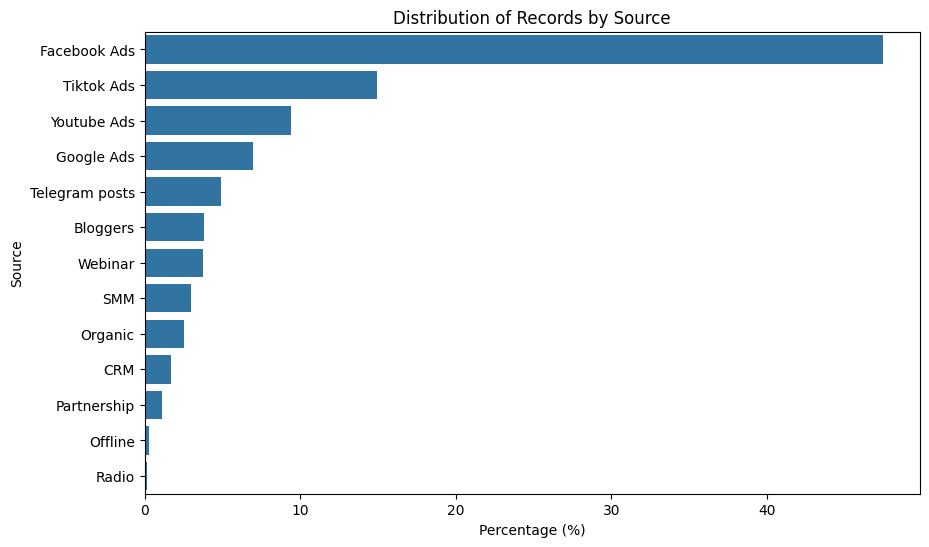

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=source_distribution,
    x="Percentage (%)",
    y=source_distribution.index
)

plt.title("Distribution of Records by Source")
plt.xlabel("Percentage (%)")
plt.ylabel("Source")

plt.show()

### AdGroup Distribution

In [ ]:
print("AdGroup Distribution")

spend["AdGroup"].value_counts(dropna=False)

AdGroup Distribution


,count
AdGroup,
NaN,6735
wide,5451
recentlymoved,1442
women,1274
LAL1,1220
Com_august,1073
interest_work_WebDev,733
interest_programming_WebDev,636
b,566


English:

Among the unique AdGroup values, two values contain the suffix Copy: interest_programming – Copy and interest_dataanalytics – Copy. We will examine these records separately to determine whether they require any data cleaning.

### AdGroup Investigation

In [ ]:
print("AdGroups Containing 'Copy'")

spend[
    spend["AdGroup"].str.contains("Copy", case=False, na=False)
]

AdGroups Containing 'Copy'


,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
100,2023-07-07,Facebook Ads,05.07.23interests_DE,18,0.12,0,interest_programming – Copy,b2
101,2023-07-07,Facebook Ads,05.07.23interests_DE,23,0.30,0,interest_programming – Copy,b3
102,2023-07-07,Facebook Ads,05.07.23interests_DE,29,0.36,0,interest_dataanalytics – Copy,b4
103,2023-07-07,Facebook Ads,05.07.23interests_DE,24,0.34,0,interest_dataanalytics – Copy,b2
114,2023-07-07,Facebook Ads,05.07.23interests_DE,1,0.00,0,interest_dataanalytics – Copy,b3
125,2023-07-07,Facebook Ads,05.07.23interests_DE,86,1.02,2,interest_programming – Copy,b4
137,2023-07-08,Facebook Ads,05.07.23interests_DE,70,0.92,1,interest_dataanalytics – Copy,b2
142,2023-07-08,Facebook Ads,05.07.23interests_DE,14,0.22,0,interest_programming – Copy,b4
151,2023-07-08,Facebook Ads,05.07.23interests_DE,1,0.00,0,interest_programming – Copy,b2
159,2023-07-08,Facebook Ads,05.07.23interests_DE,1,0.00,0,interest_dataanalytics – Copy,b3


In [ ]:
print("Campaigns and Ads for AdGroups Containing 'Copy'" + "\n")

spend[
    spend["AdGroup"].str.contains("Copy", case=False, na=False)
][
    ["Campaign", "AdGroup", "Ad"]
].value_counts()

Campaigns and Ads for AdGroups Containing 'Copy'



Campaign              AdGroup                        Ad
05.07.23interests_DE  interest_dataanalytics – Copy  b2    4
                      interest_programming – Copy    b2    3
                                                     b4    3
                      interest_dataanalytics – Copy  b3    2
                      interest_programming – Copy    b3    2
                      interest_dataanalytics – Copy  b4    1
Name: count, dtype: int64

Conclusion:

The AdGroup values containing Copy appear in 15 records within the same Facebook Ads campaign. The records span different dates, contain different ads, and have different performance metrics. Therefore, these AdGroup values are considered valid and are retained unchanged.

## 1.5 Data Validation

In [ ]:
numeric_columns = spend.select_dtypes(include="number").columns

print("Negative Values:\n")

for column in numeric_columns:
    print(f"{column}: {(spend[column] < 0).sum()}")

Negative Values:

Impressions: 0
Spend: 0
Clicks: 0


In [ ]:
print("Zero Values:\n")

for column in numeric_columns:
    print(f"{column}: {(spend[column] == 0).sum()}")

Zero Values:

Impressions: 5658
Spend: 6414
Clicks: 8633


In [ ]:
zero_by_source = (
    spend.groupby("Source")[["Impressions", "Clicks", "Spend"]]
    .agg(lambda x: (x == 0).sum())
    .sort_values("Clicks", ascending=False)
)

print("Rows with Zero Impressions, Clicks, and Spend by Source")
display(zero_by_source)

Rows with Zero Impressions, Clicks, and Spend by Source


,Impressions,Clicks,Spend
Source,,,
Facebook Ads,537,4186,844
Tiktok Ads,866,1111,868
Youtube Ads,497,676,505
Webinar,458,571,462
Bloggers,519,570,712
Telegram posts,526,564,793
Google Ads,517,523,523
SMM,543,181,518
Partnership,234,129,234


In [ ]:
print("Rows with 0 Impressions and Clicks > 0")

spend[
    (spend["Impressions"] == 0) &
    (spend["Clicks"] > 0)
]

Rows with 0 Impressions and Clicks > 0


,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
13,2023-07-03,SMM,NaN,0,0.0,5,NaN,NaN
15,2023-07-03,Organic,NaN,0,0.0,48,NaN,NaN
17,2023-07-04,Organic,NaN,0,0.0,37,NaN,NaN
24,2023-07-04,SMM,NaN,0,0.0,2,NaN,NaN
38,2023-07-05,Organic,NaN,0,0.0,43,NaN,NaN
...,...,...,...,...,...,...,...,...
20387,2024-06-20,CRM,NaN,0,0.0,14,NaN,NaN
20405,2024-06-20,Organic,NaN,0,0.0,11,NaN,NaN
20413,2024-06-20,SMM,NaN,0,0.0,1,NaN,NaN
20419,2024-06-20,Partnership,NaN,0,0.0,1,NaN,NaN


In [ ]:
print("Rows with 0 Impressions and Spend > 0")

spend[
    (spend["Impressions"] == 0) &
    (spend["Spend"] > 0)
]

Rows with 0 Impressions and Spend > 0


,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
1585,2023-08-08,SMM,NaN,0,100.00,30,NaN,NaN
4074,2023-09-23,SMM,NaN,0,250.00,21,NaN,NaN
6835,2023-11-18,SMM,NaN,0,110.00,13,NaN,NaN
7841,2023-12-12,SMM,NaN,0,165.00,27,NaN,NaN
8315,2023-12-22,SMM,NaN,0,50.00,22,NaN,NaN
9597,2024-01-17,SMM,NaN,0,30.00,21,NaN,NaN
10022,2024-01-24,SMM,NaN,0,300.00,50,NaN,NaN
10335,2024-01-30,SMM,NaN,0,640.00,277,NaN,NaN
10791,2024-02-07,SMM,NaN,0,595.00,240,NaN,NaN
11458,2024-02-19,SMM,NaN,0,80.00,60,NaN,NaN


Note:

A large number of rows have Impressions = 0 while Clicks > 0 or Spend > 0. Since this pattern occurs frequently, these records cannot be treated as errors and removed without further investigation. Therefore, these cases will be analyzed by Source.

In [ ]:
print("0 Impressions and Clicks > 0 by Source")

spend[
    (spend["Impressions"] == 0) &
    (spend["Clicks"] > 0)
]["Source"].value_counts()

0 Impressions and Clicks > 0 by Source


,count
Source,
Organic,508
SMM,416
CRM,315
Partnership,105
Offline,16
Bloggers,9
Telegram posts,1


In [ ]:
print("0 Impressions and Spend > 0 by Source")

spend[
    (spend["Impressions"] == 0) &
    (spend["Spend"] > 0)
]["Source"].value_counts()

0 Impressions and Spend > 0 by Source


,count
Source,
SMM,25
Radio,6
Telegram posts,3


Conclusion:

Rows with Impressions = 0 and non-zero Clicks or Spend occur in sources such as Organic, SMM, CRM, Partnership, Offline, Bloggers, Radio, and Telegram posts, where impressions cannot always be directly tracked. Therefore, these records are valid and are retained without changes.

## 1.6 Final Data Check

In [ ]:
print("FINAL DATASET SHAPE")
print(spend.shape)

print("\nMISSING VALUES")
print(spend.isna().sum())

print()
print("FINAL DATASET DESCRIBE")
display(spend.describe())

FINAL DATASET SHAPE
(20517, 8)

MISSING VALUES
Date              0
Source            0
Campaign       5901
Impressions       0
Spend             0
Clicks            0
AdGroup        6735
Ad             6735
dtype: int64

FINAL DATASET DESCRIBE


,Date,Impressions,Spend,Clicks
count,20517,20517.000000,20517.000000,20517.000000
mean,2024-01-14 21:50:34.654189312,2487.451431,7.258139,24.237218
min,2023-07-03 00:00:00,0.000000,0.000000,0.000000
25%,2023-10-12 00:00:00,0.000000,0.000000,0.000000
50%,2024-01-28 00:00:00,64.000000,0.580000,1.000000
75%,2024-04-16 00:00:00,723.000000,5.790000,13.000000
max,2024-06-21 00:00:00,431445.000000,774.000000,2415.000000
std,NaN,11512.317881,26.920710,85.742144


Conclusion

The final Spend dataset contains 20,517 records and 8 columns. Missing values occur only in Campaign, AdGroup, and Ad, and their distribution depends on the marketing source. This can be explained by differences in advertising structures and tracking practices: not all sources provide campaign-level information, while AdGroup and Ad details are mainly associated with paid advertising platforms. Therefore, these missing values were retained without imputation.

The numerical columns contain no negative values but have a substantial number of zeros. At least 25% of records have zero Impressions, Clicks, and Spend. Some sources, including Organic, SMM, CRM, and Partnership, report clicks despite zero impressions, while SMM, Radio, and Telegram posts also contain advertising costs without recorded impressions. This is plausible for channels where impressions are not consistently tracked, so zero values were preserved.

The distributions of Impressions, Clicks, and Spend are strongly right-skewed: their means exceed their medians, and maximum values are substantially higher than the 75th percentiles. This may reflect differences in campaign scale, reach, and advertising costs. Since these extreme values are plausible and no errors were confirmed, they were retained for further analysis.

# 2. Dataset Contacts

## 2.1 Data Loading

In [ ]:
contacts = pd.read_excel('/content/drive/MyDrive/Final_Project/Contacts (Done).xlsx', dtype={'Id': str})

contacts.head()

,Id,Contact Owner Name,Created Time,Modified Time
0,5805028000000645014,Rachel White,27.06.2023 11:28,22.12.2023 13:34
1,5805028000000872003,Charlie Davis,03.07.2023 11:31,21.05.2024 10:23
2,5805028000000889001,Bob Brown,02.07.2023 22:37,21.12.2023 13:17
3,5805028000000907006,Bob Brown,03.07.2023 05:44,29.12.2023 15:20
4,5805028000000939010,Nina Scott,04.07.2023 10:11,16.04.2024 16:14


## 2.2 Initial Data Inspection

### Dataset Overview

In [ ]:
print("CONTACTS DATASET SHAPE")
print(contacts.shape)

print("\n" + "=" * 80 + "\n")

print("DATA TYPES AND MISSING VALUES")
contacts.info()

CONTACTS DATASET SHAPE
(18548, 4)


DATA TYPES AND MISSING VALUES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18548 entries, 0 to 18547
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Id                  18548 non-null  object
 1   Contact Owner Name  18548 non-null  object
 2   Created Time        18548 non-null  object
 3   Modified Time       18548 non-null  object
dtypes: object(4)
memory usage: 579.8+ KB


### Date and Time Conversion

In [ ]:
time_columns = ["Created Time", "Modified Time"]

for column in time_columns:
    contacts[column] = pd.to_datetime(
        contacts[column],
        format="%d.%m.%Y %H:%M",
        errors="raise"
    )

contacts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18548 entries, 0 to 18547
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Id                  18548 non-null  object        
 1   Contact Owner Name  18548 non-null  object        
 2   Created Time        18548 non-null  datetime64[ns]
 3   Modified Time       18548 non-null  datetime64[ns]
dtypes: datetime64[ns](2), object(2)
memory usage: 579.8+ KB


In [ ]:
print("DATE RANGES")

for column in ["Created Time", "Modified Time"]:
    print(f"\n{column}")
    print("Min:", contacts[column].min())
    print("Max:", contacts[column].max())

DATE RANGES

Created Time
Min: 2023-06-27 11:28:00
Max: 2024-06-21 15:30:00

Modified Time
Min: 2023-07-06 10:54:00
Max: 2024-06-21 15:32:00


#### Date Consistency Check

In [ ]:
print("Records with Modified Time Earlier than Created Time: ", end=" ")

print(
    (contacts["Modified Time"] < contacts["Created Time"]).sum()
)

Records with Modified Time Earlier than Created Time:  0


Conclusion:

No records have a Modified Time earlier than their Created Time. The date sequence is logically consistent across the dataset.

### Missing Values

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": contacts.isna().sum(),
    "Missing Percentage (%)": round(contacts.isna().sum() / contacts.shape[0] * 100, 2)
})

missing_values

,Missing Count,Missing Percentage (%)
Id,0,0.0
Contact Owner Name,0,0.0
Created Time,0,0.0
Modified Time,0,0.0


Conclusion:

No missing values were found in the Contacts dataset at this stage.

### Unique Values

In [ ]:
print(contacts.shape, "\n")

print("Number of Unique Values")

contacts.nunique(dropna=False)

(18548, 4) 

Number of Unique Values


,0
Id,18548
Contact Owner Name,28
Created Time,17921
Modified Time,16580


## 2.3 Duplicates

Note:

The number of unique Id values is equal to the total number of records, confirming that each contact has a unique identifier. Therefore, duplicate records are checked excluding the Id column to identify contacts with different IDs but identical values in all other fields.

In [ ]:
duplicate_columns = contacts.columns.drop("Id")

print("Number of Duplicated Rows Excluding Id:")
print(contacts.duplicated(subset=duplicate_columns).sum())

Number of Duplicated Rows Excluding Id:
38


In [ ]:
contacts[
    contacts.duplicated(
        subset=duplicate_columns,
        keep=False
    )
].sort_values(list(duplicate_columns))

,Id,Contact Owner Name,Created Time,Modified Time
14360,5805028000044178663,Amy Green,2024-04-16 18:13:00,2024-04-16 20:13:00
14376,5805028000044202223,Amy Green,2024-04-16 18:13:00,2024-04-16 20:13:00
17711,5805028000053716641,Ben Hall,2024-06-06 17:48:00,2024-06-06 19:48:00
17717,5805028000053717839,Ben Hall,2024-06-06 17:48:00,2024-06-06 19:48:00
203,5805028000001949074,Bob Brown,2023-07-17 18:40:00,2023-07-17 18:40:00
...,...,...,...,...
8039,5805028000026092710,Ulysses Adams,2024-01-15 20:54:00,2024-01-15 22:56:00
11126,5805028000035548331,Ulysses Adams,2024-03-04 20:00:00,2024-03-04 22:04:00
11142,5805028000035573410,Ulysses Adams,2024-03-04 20:00:00,2024-03-04 22:04:00
9317,5805028000029776281,Victor Barnes,2024-02-02 13:46:00,2024-02-02 15:47:00


In [ ]:
duplicate_groups = (
    contacts[
        contacts.duplicated(
            subset=duplicate_columns,
            keep=False
        )
    ]
    .groupby(list(duplicate_columns), dropna=False)
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

duplicate_groups

,Contact Owner Name,Created Time,Modified Time,Count
25,Rachel White,2024-06-10 09:00:00,2024-06-10 09:33:00,6
29,Ulysses Adams,2024-01-15 20:20:00,2024-01-15 22:21:00,3
0,Amy Green,2024-04-16 18:13:00,2024-04-16 20:13:00,2
1,Ben Hall,2024-06-06 17:48:00,2024-06-06 19:48:00,2
2,Bob Brown,2023-07-17 18:40:00,2023-07-17 18:40:00,2
5,Bob Brown,2023-08-10 15:59:00,2023-08-10 15:59:00,2
6,Bob Brown,2023-08-14 12:31:00,2023-08-14 12:31:00,2
3,Bob Brown,2023-07-18 16:53:00,2023-07-18 16:53:00,2
4,Bob Brown,2023-07-21 12:26:00,2023-07-21 12:26:00,2
9,Ian Miller,2023-10-11 13:45:00,2023-10-11 13:45:00,2


Conclusion:

All records have unique Id values. When Id was excluded from the duplicate check, 38 repeated records were identified across 33 groups, involving 71 records in total.  
Identical Contact Owner Name, Created Time, and Modified Time values can occur for different contacts, as multiple contacts may be created for the same owner at the same time and timestamps are generated automatically. Therefore, these records are valid and are retained.

## 2.4 Categorical Data Analysis

### Contact Owner Name Distribution

In [ ]:
print("Contact Owner Name Distribution")

contacts["Contact Owner Name"].value_counts(dropna=False)

Contact Owner Name Distribution


,count
Contact Owner Name,
Charlie Davis,2018
Ulysses Adams,1816
Julia Nelson,1769
Paula Underwood,1487
Quincy Vincent,1416
Nina Scott,1150
Ben Hall,1038
Victor Barnes,967
Cara Iverson,880


In [ ]:
print("Data Types in Contact Owner Name")

contacts["Contact Owner Name"].map(type).value_counts()

Data Types in Contact Owner Name


,count
Contact Owner Name,
<class 'str'>,18547
<class 'bool'>,1


In [ ]:
print("Record with Contact Owner Name = False")

false_record = contacts[
    contacts["Contact Owner Name"] == False
]

false_record

Record with Contact Owner Name = False


,Id,Contact Owner Name,Created Time,Modified Time
2197,5805028000008772190,False,2023-09-24 09:01:00,2023-10-13 16:44:00


In [ ]:
# Check contact owners who were active on the same date

target_date = false_record["Created Time"].iloc[0].date()


contacts[
    contacts["Created Time"].dt.date == target_date
]["Contact Owner Name"].value_counts(dropna=False)

,count
Contact Owner Name,
Jane Smith,13
George King,11
Julia Nelson,5
Mason Roberts,4
Ulysses Adams,3
Diana Evans,2
Bob Brown,2
Charlie Davis,2
False,1


Conclusion:

Several contact owners were active on that day, so the correct owner cannot be reliably determined. Since False is an invalid value for Contact Owner Name, it was replaced with a missing value. The contact record was retained because the corresponding Contact ID is present in both the Deals and Calls datasets (see Contact ID Validation in the Deals and Calls sections).

In [ ]:
contacts.loc[
    contacts["Contact Owner Name"] == False,
    "Contact Owner Name"
] = pd.NA

## 2.5 Final Data Check

In [ ]:
print("FINAL DATASET SHAPE")
print(contacts.shape)

print("\nMISSING VALUES")
print(contacts.isna().sum())

print()

print("FINAL DATASET DESCRIBE")
display(contacts.describe())

FINAL DATASET SHAPE
(18548, 4)

MISSING VALUES
Id                    0
Contact Owner Name    1
Created Time          0
Modified Time         0
dtype: int64

FINAL DATASET DESCRIBE


,Created Time,Modified Time
count,18548,18548
mean,2024-01-24 14:00:21.679965696,2024-02-15 07:41:24.814535168
min,2023-06-27 11:28:00,2023-07-06 10:54:00
25%,2023-11-15 16:40:45,2023-12-09 12:43:00
50%,2024-02-01 18:30:00,2024-02-28 22:21:30
75%,2024-04-12 16:37:15,2024-04-26 22:02:30
max,2024-06-21 15:30:00,2024-06-21 15:32:00


Conclusion


The final Contacts dataset contains 18,548 records and 4 columns. Only one value is missing in Contact Owner Name: the original False value was replaced with NaN because it does not represent a valid contact owner. The record was retained to preserve its relationships with other datasets.

Created Time ranges from June 2023 to June 2024, while Modified Time ranges from July 2023 to June 2024. The median modification date is later than the median creation date, reflecting subsequent updates to contact records. No cases of Modified Time preceding Created Time were found.

# 3. Dataset Calls

## 3.1 Data Loading

In [ ]:
calls = pd.read_excel('/content/drive/MyDrive/Final_Project/Calls (Done).xlsx', dtype={'Id': str, "CONTACTID": str})
calls.head()

,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Dialled Number,Outgoing Call Status,Scheduled in CRM,Tag
0,5805028000000805001,30.06.2023 08:43,John Doe,NaN,Inbound,171.0,Received,NaN,NaN,NaN,NaN
1,5805028000000768006,30.06.2023 08:46,John Doe,NaN,Outbound,28.0,Attended Dialled,NaN,Completed,0.0,NaN
2,5805028000000764027,30.06.2023 08:59,John Doe,NaN,Outbound,24.0,Attended Dialled,NaN,Completed,0.0,NaN
3,5805028000000787003,30.06.2023 09:20,John Doe,5805028000000645014,Outbound,6.0,Attended Dialled,NaN,Completed,0.0,NaN
4,5805028000000768019,30.06.2023 09:30,John Doe,5805028000000645014,Outbound,11.0,Attended Dialled,NaN,Completed,0.0,NaN


## 3.2 Initial Data Inspection

### Dataset Overview

In [ ]:
print("CALLS DATASET SHAPE")
print(calls.shape)

print("\nDATA TYPES AND MISSING VALUES")
calls.info()

print("\nDESCRIBE")
display(calls.describe())

CALLS DATASET SHAPE
(95874, 11)

DATA TYPES AND MISSING VALUES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95874 entries, 0 to 95873
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Id                          95874 non-null  object 
 1   Call Start Time             95874 non-null  object 
 2   Call Owner Name             95874 non-null  object 
 3   CONTACTID                   91941 non-null  object 
 4   Call Type                   95874 non-null  object 
 5   Call Duration (in seconds)  95791 non-null  float64
 6   Call Status                 95874 non-null  object 
 7   Dialled Number              0 non-null      float64
 8   Outgoing Call Status        86875 non-null  object 
 9   Scheduled in CRM            86875 non-null  float64
 10  Tag                         0 non-null      float64
dtypes: float64(4), object(7)
memory usage: 8.0+ MB

DESCRIBE


,Call Duration (in seconds),Dialled Number,Scheduled in CRM,Tag
count,95791.000000,0.0,86875.000000,0.0
mean,164.977263,NaN,0.001635,NaN
std,401.410826,NaN,0.040397,NaN
min,0.000000,NaN,0.000000,NaN
25%,4.000000,NaN,0.000000,NaN
50%,8.000000,NaN,0.000000,NaN
75%,98.000000,NaN,0.000000,NaN
max,7625.000000,NaN,1.000000,NaN


### Date and Time Conversion

In [ ]:
calls["Call Start Time"] = pd.to_datetime(
    calls["Call Start Time"],
    format="%d.%m.%Y %H:%M",
    errors="raise"
)

calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95874 entries, 0 to 95873
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Id                          95874 non-null  object        
 1   Call Start Time             95874 non-null  datetime64[ns]
 2   Call Owner Name             95874 non-null  object        
 3   CONTACTID                   91941 non-null  object        
 4   Call Type                   95874 non-null  object        
 5   Call Duration (in seconds)  95791 non-null  float64       
 6   Call Status                 95874 non-null  object        
 7   Dialled Number              0 non-null      float64       
 8   Outgoing Call Status        86875 non-null  object        
 9   Scheduled in CRM            86875 non-null  float64       
 10  Tag                         0 non-null      float64       
dtypes: datetime64[ns](1), float64(4), object(6)
memory usa

### Missing Values

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": calls.isna().sum(),
    "Missing Percentage (%)": round(calls.isna().sum() / calls.shape[0] * 100, 2)
})

missing_values

,Missing Count,Missing Percentage (%)
Id,0,0.00
Call Start Time,0,0.00
Call Owner Name,0,0.00
CONTACTID,3933,4.10
Call Type,0,0.00
Call Duration (in seconds),83,0.09
Call Status,0,0.00
Dialled Number,95874,100.00
Outgoing Call Status,8999,9.39
Scheduled in CRM,8999,9.39


In [ ]:
calls = calls.drop(
    columns=["Dialled Number", "Tag"]
)

Conclusion:

Dialled Number and Tag contain only missing values and provide no information for the analysis. Therefore, both columns are removed from the dataset.

### Unique Values

In [ ]:
print(calls.shape, "\n")

print("Number of Unique Values")

calls.nunique(dropna=False)

(95874, 9) 

Number of Unique Values


,0
Id,95874
Call Start Time,68445
Call Owner Name,33
CONTACTID,15215
Call Type,3
Call Duration (in seconds),2620
Call Status,11
Outgoing Call Status,5
Scheduled in CRM,3


## 3.3 Dublicates

In [ ]:
dup_cols = calls.columns.drop("Id")

print(
    "Duplicate Rows Excluding Id:",
    calls.duplicated(subset=dup_cols).sum()
)

print(
    "All Rows Involved in Duplicates Excluding Id:",
    calls.duplicated(
        subset=dup_cols,
        keep=False
    ).sum()
)

Duplicate Rows Excluding Id: 3257
All Rows Involved in Duplicates Excluding Id: 6382


In [ ]:
calls[
    calls.duplicated(
        subset=dup_cols,
        keep=False
    )
].sort_values(
    by=dup_cols.tolist()
).head(8)

,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
34,5805028000001140014,2023-07-06 17:15:00,Alice Johnson,5805028000001129001,Outbound,0.0,Unattended Dialled,Completed,0.0
35,5805028000001167001,2023-07-06 17:15:00,Alice Johnson,5805028000001129001,Outbound,0.0,Unattended Dialled,Completed,0.0
101,5805028000001372054,2023-07-08 16:43:00,John Doe,NaN,Missed,0.0,Missed,NaN,NaN
102,5805028000001348077,2023-07-08 16:43:00,John Doe,NaN,Missed,0.0,Missed,NaN,NaN
254,5805028000001568042,2023-07-12 19:23:00,Jane Smith,5805028000001552025,Outbound,0.0,Unattended Dialled,Completed,0.0
255,5805028000001546030,2023-07-12 19:23:00,Jane Smith,5805028000001552025,Outbound,0.0,Unattended Dialled,Completed,0.0
277,5805028000001663093,2023-07-13 12:26:00,Jane Smith,NaN,Missed,0.0,Missed,NaN,NaN
278,5805028000001679013,2023-07-13 12:26:00,Jane Smith,NaN,Missed,0.0,Missed,NaN,NaN


In [ ]:
dup_groups = (
    calls.groupby(
        dup_cols.tolist(),
        dropna=False
    )
    .size()
    .reset_index(name="Count")
)

dup_groups = dup_groups[
    dup_groups["Count"] > 1
]

In [ ]:
print("Duplicate Group Size Distribution")

(
    dup_groups["Count"]
    .value_counts()
    .sort_index()
    .rename_axis("Records per Group")
    .reset_index(name="Number of Groups")
)

Duplicate Group Size Distribution


,Records per Group,Number of Groups
0,2,3013
1,3,93
2,4,18
3,5,1


In [ ]:
print("Duplicate Group with 5 Identical Records")

group_size = calls.groupby(
    dup_cols.tolist(),
    dropna=False
)["Id"].transform("size")

calls[
    group_size == 5
]

Duplicate Group with 5 Identical Records


,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
9522,5805028000008553249,2023-09-22 15:51:00,Charlie Davis,5805028000008466109,Outbound,0.0,Unattended Dialled,Completed,0.0
9523,5805028000008575347,2023-09-22 15:51:00,Charlie Davis,5805028000008466109,Outbound,0.0,Unattended Dialled,Completed,0.0
9524,5805028000008566231,2023-09-22 15:51:00,Charlie Davis,5805028000008466109,Outbound,0.0,Unattended Dialled,Completed,0.0
9525,5805028000008566243,2023-09-22 15:51:00,Charlie Davis,5805028000008466109,Outbound,0.0,Unattended Dialled,Completed,0.0
9526,5805028000008590206,2023-09-22 15:51:00,Charlie Davis,5805028000008466109,Outbound,0.0,Unattended Dialled,Completed,0.0


Note:

Call Start Time in the source data is recorded only to the minute; exact start seconds are unavailable. Therefore, several calls with the same recorded start time may actually represent separate call attempts made within the same minute. For example, five unanswered calls with very short or zero duration could theoretically occur within one minute and should not automatically be treated as duplicates.
A call may also start within the recorded minute and end in the next one. Therefore, only the time required until the start of the last call is considered: (Count - 1) × Call Duration. No additional gap between calls is assumed because the technical call initiation process is unknown.

In [ ]:
print("Call Duration Distribution in Duplicate Groups")

dup_groups["Call Duration (in seconds)"].value_counts(
    dropna=False
).sort_index()

Call Duration Distribution in Duplicate Groups


,count
Call Duration (in seconds),
0.0,1946
1.0,6
2.0,5
3.0,8
4.0,244
...,...
1369.0,1
1624.0,1
1721.0,1


In [ ]:
dup_groups = dup_groups[
    dup_groups["Call Duration (in seconds)"] > 0
].copy()

In [ ]:
dup_groups["Start Span (seconds)"] = (
    (dup_groups["Count"] - 1)
    * dup_groups["Call Duration (in seconds)"]
)

In [ ]:
print(
    "Duplicate Groups with Start Span >= 60 Seconds:",
    (dup_groups["Start Span (seconds)"] >= 60).sum()
)

print("\nDuplicate Groups with Start Span >= 60 Seconds")

dup_groups[
    dup_groups["Start Span (seconds)"] >= 60
].sort_values(
    "Start Span (seconds)",
    ascending=False
).head()

Duplicate Groups with Start Span >= 60 Seconds: 74

Duplicate Groups with Start Span >= 60 Seconds


,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM,Count,Start Span (seconds)
54015,2024-03-12 20:01:00,Ben Hall,5805028000036395770,Outbound,2885.0,Attended Dialled,Completed,0.0,2,2885.0
51631,2024-03-04 18:22:00,Quincy Vincent,5805028000035497251,Outbound,1721.0,Attended Dialled,Completed,0.0,2,1721.0
51113,2024-03-01 18:02:00,John Doe,5805028000024296179,Inbound,1624.0,Received,NaN,NaN,2,1624.0
53565,2024-03-11 17:03:00,Julia Nelson,5805028000024502945,Outbound,1369.0,Attended Dialled,Completed,0.0,2,1369.0
86239,2024-06-05 18:36:00,Amy Green,5805028000053576590,Outbound,1263.0,Attended Dialled,Completed,0.0,2,1263.0


In [ ]:
dup_groups["Max Calls"] = np.minimum(
    dup_groups["Count"],
    np.ceil(
        60 / dup_groups["Call Duration (in seconds)"]
    ).astype(int)
)

dup_groups["Calls to Remove"] = (
    dup_groups["Count"] - dup_groups["Max Calls"]
)

In [ ]:
print("Calls to Remove Distribution")

display(
    dup_groups["Calls to Remove"]
    .value_counts()
    .sort_index()
)

print("\nDuplicate Groups with Calls to Remove")

display(dup_groups[
    dup_groups["Calls to Remove"] > 0
].sort_values(
    "Calls to Remove",
    ascending=False
))

Calls to Remove Distribution


,count
Calls to Remove,
0,1101
1,74



Duplicate Groups with Calls to Remove


,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM,Count,Start Span (seconds),Max Calls,Calls to Remove
11818,2023-10-04 17:32:00,Kevin Parker,5805028000008350093,Outbound,984.0,Attended Dialled,Completed,0.0,2,984.0,1,1
51098,2024-03-01 17:44:00,Victor Barnes,5805028000012441136,Outbound,117.0,Attended Dialled,Completed,0.0,2,117.0,1,1
51100,2024-03-01 17:48:00,Amy Green,NaN,Outbound,114.0,Attended Dialled,Completed,0.0,2,114.0,1,1
51106,2024-03-01 17:52:00,Amy Green,NaN,Outbound,60.0,Attended Dialled,Completed,0.0,2,60.0,1,1
51107,2024-03-01 17:53:00,Amy Green,5805028000034592001,Outbound,925.0,Attended Dialled,Completed,0.0,2,925.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
86228,2024-06-05 18:09:00,Amy Green,5805028000053550568,Outbound,287.0,Attended Dialled,Completed,0.0,2,287.0,1,1
86229,2024-06-05 18:13:00,Cara Iverson,5805028000053534166,Outbound,1011.0,Attended Dialled,Completed,0.0,2,1011.0,1,1
86239,2024-06-05 18:36:00,Amy Green,5805028000053576590,Outbound,1263.0,Attended Dialled,Completed,0.0,2,1263.0,1,1
86245,2024-06-05 19:01:00,Julia Nelson,5805028000053576712,Outbound,648.0,Attended Dialled,Completed,0.0,2,648.0,1,1


In [ ]:
print(
    "Total Calls to Remove:",
    dup_groups["Calls to Remove"].sum()
)

Total Calls to Remove: 74


In [ ]:
print("Problematic Groups by Size")

(
    dup_groups[
        dup_groups["Calls to Remove"] > 0
    ]["Count"]
    .value_counts()
    .sort_index()
)

Problematic Groups by Size


,count
Count,
2,74


Note:

All 74 problematic duplicate groups contain exactly two records, and only one record needs to be removed from each group. Therefore, the duplicate removal can be simplified: for duplicated calls with a duration of at least 60 seconds, the first record is retained and the repeated record is removed.

In [ ]:
remove_idx = calls[
    (calls["Call Duration (in seconds)"] >= 60)
    & calls.duplicated(
        subset=dup_cols,
        keep="first"
    )
].index

print("Rows to Remove:", len(remove_idx))

Rows to Remove: 74


In [ ]:
calls = calls.drop(
    index=remove_idx
).reset_index(drop=True)

print("Calls Shape After Removing Duplicates:", calls.shape)

Calls Shape After Removing Duplicates: (95800, 9)


In [ ]:
print(
    "Duplicate Rows Excluding Id:",
    calls.duplicated(subset=dup_cols).sum()
)

print(
    "All Rows Involved in Duplicates Excluding Id:",
    calls.duplicated(
        subset=dup_cols,
        keep=False
    ).sum()
)

Duplicate Rows Excluding Id: 3183
All Rows Involved in Duplicates Excluding Id: 6234


Conclusion:

Duplicate records were identified using all call attributes except the unique Id. Since Call Start Time is recorded only to the minute, identical records were not automatically treated as duplicates, as several separate call attempts could occur within the same minute. To identify records that could not represent separate sequential calls within the same recorded minute, the minimum time required for their starts was evaluated using (Count - 1) × Call Duration. A total of 74 groups required at least 60 seconds. All of these groups contained exactly two records and required the removal of one record. Therefore, 74 duplicate records were removed, while the remaining repeated records were retained because there was insufficient evidence to classify them as technical duplicates.

## 3.4 Categorical Data Analysis

### Call Type

In [ ]:
print("Call Type Distribution")

pd.DataFrame({
    "Count": calls["Call Type"].value_counts(dropna=False),
    "Percentage (%)": (calls["Call Type"]
        .value_counts(dropna=False, normalize=True) * 100)
        .round(2)
})

Call Type Distribution


,Count,Percentage (%)
Call Type,,
Outbound,86807,90.61
Missed,5921,6.18
Inbound,3072,3.21


### Call Status

In [ ]:
print("Call Status Distribution")

pd.DataFrame({
    "Count": calls["Call Status"].value_counts(dropna=False),
    "Percentage (%)": (calls["Call Status"]
        .value_counts(dropna=False, normalize=True) * 100)
        .round(2)
})

Call Status Distribution


,Count,Percentage (%)
Call Status,,
Attended Dialled,70635,73.73
Unattended Dialled,16030,16.73
Missed,5922,6.18
Received,3071,3.21
Overdue,60,0.06
Scheduled Attended Delay,22,0.02
Cancelled,20,0.02
Scheduled Unattended Delay,17,0.02
Scheduled Attended,14,0.01


In [ ]:
print("Call Type and Call Status Distribution")

calls.groupby(
    ["Call Type", "Call Status"],
    dropna=False
).size().reset_index(name="Count")

Call Type and Call Status Distribution


,Call Type,Call Status,Count
0,Inbound,Missed,1
1,Inbound,Received,3071
2,Missed,Missed,5921
3,Outbound,Attended Dialled,70635
4,Outbound,Cancelled,20
5,Outbound,Overdue,60
6,Outbound,Scheduled,3
7,Outbound,Scheduled Attended,14
8,Outbound,Scheduled Attended Delay,22
9,Outbound,Scheduled Unattended,6


In [ ]:
print("Inbound Call with Missed Status")

calls[
    (calls["Call Type"] == "Inbound")
    & (calls["Call Status"] == "Missed")
]

Inbound Call with Missed Status


,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
55365,5805028000037112059,2024-03-12 16:47:00,Nina Scott,5805028000032522621,Inbound,0.0,Missed,NaN,NaN


### Outgoing Call Status

In [ ]:
print("Outgoing Call Status Distribution")

pd.DataFrame({
    "Count": calls["Outgoing Call Status"].value_counts(dropna=False),
    "Percentage (%)": (calls["Outgoing Call Status"]
        .value_counts(dropna=False, normalize=True) * 100)
        .round(2)
})

Outgoing Call Status Distribution


,Count,Percentage (%)
Outgoing Call Status,,
Completed,86724,90.53
NaN,8993,9.39
Overdue,60,0.06
Cancelled,20,0.02
Scheduled,3,0.00


In [ ]:
print("Call Type and Outgoing Call Status Distribution")

calls.groupby(
    ["Call Type", "Outgoing Call Status"],
    dropna=False
).size().reset_index(name="Count")

Call Type and Outgoing Call Status Distribution


,Call Type,Outgoing Call Status,Count
0,Inbound,NaN,3072
1,Missed,NaN,5921
2,Outbound,Cancelled,20
3,Outbound,Completed,86724
4,Outbound,Overdue,60
5,Outbound,Scheduled,3


Conclusion:

Outgoing Call Status is applicable only to Outbound calls. All 86,807 outbound calls have a corresponding outgoing call status, while all Inbound and Missed calls contain missing values in this field. Therefore, the 8,993 missing values are structurally expected and do not represent a data quality issue. No changes are required.

### Scheduled in CRM

In [ ]:
print("Scheduled in CRM Distribution")

pd.DataFrame({
    "Count": calls["Scheduled in CRM"].value_counts(dropna=False),
    "Percentage (%)": (calls["Scheduled in CRM"]
        .value_counts(dropna=False, normalize=True) * 100)
        .round(2)
})

Scheduled in CRM Distribution


,Count,Percentage (%)
Scheduled in CRM,,
0.0,86665,90.46
NaN,8993,9.39
1.0,142,0.15


In [ ]:
print("Call Type and Scheduled in CRM Distribution")

calls.groupby(
    ["Call Type", "Scheduled in CRM"],
    dropna=False
).size().reset_index(name="Count")

Call Type and Scheduled in CRM Distribution


,Call Type,Scheduled in CRM,Count
0,Inbound,NaN,3072
1,Missed,NaN,5921
2,Outbound,0.0,86665
3,Outbound,1.0,142


In [ ]:
print("Scheduled in CRM and Call Status Distribution")

calls.groupby(
    ["Scheduled in CRM", "Call Status"],
    dropna=False
).size().reset_index(name="Count")

Scheduled in CRM and Call Status Distribution


,Scheduled in CRM,Call Status,Count
0,0.0,Attended Dialled,70635
1,0.0,Unattended Dialled,16030
2,1.0,Cancelled,20
3,1.0,Overdue,60
4,1.0,Scheduled,3
5,1.0,Scheduled Attended,14
6,1.0,Scheduled Attended Delay,22
7,1.0,Scheduled Unattended,6
8,1.0,Scheduled Unattended Delay,17
9,NaN,Missed,5922


Conclusion:

Scheduled in CRM is applicable only to outbound calls and is fully consistent with Call Status. All 142 calls marked as scheduled (1) have statuses related to scheduled calls, while all 86,665 calls marked as not scheduled (0) have regular outbound call statuses (Attended Dialled or Unattended Dialled). The 8,993 missing values correspond to Inbound and Missed calls and are therefore structurally expected. No changes are required.

## 3.5 Data Validation

### Call Duration Validation

In [ ]:
print("Missing Call Duration:",
      calls["Call Duration (in seconds)"].isna().sum()
)

print("Missing Call Duration (%):",
    round(
        calls["Call Duration (in seconds)"].isna().mean() * 100,
        2
    )
)

Missing Call Duration: 83
Missing Call Duration (%): 0.09


In [ ]:
print("Calls with Missing Call Duration")

calls[
    calls["Call Duration (in seconds)"].isna()
]

Calls with Missing Call Duration


,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
21710,5805028000012419809,2023-11-15 15:00:00,Kevin Parker,NaN,Outbound,NaN,Cancelled,Cancelled,1.0
36094,5805028000012419971,2024-01-15 15:00:00,Kevin Parker,NaN,Outbound,NaN,Overdue,Overdue,1.0
36095,5805028000012419512,2024-01-15 15:00:00,Kevin Parker,NaN,Outbound,NaN,Overdue,Overdue,1.0
37599,5805028000026957356,2024-01-19 10:00:00,Victor Barnes,NaN,Outbound,NaN,Overdue,Overdue,1.0
37606,5805028000026466529,2024-01-19 10:30:00,Victor Barnes,5805028000021065227,Outbound,NaN,Overdue,Overdue,1.0
...,...,...,...,...,...,...,...,...,...
89013,5805028000053636072,2024-06-05 17:00:00,Victor Barnes,NaN,Outbound,NaN,Overdue,Overdue,1.0
89183,5805028000053651109,2024-06-06 07:00:00,Victor Barnes,NaN,Outbound,NaN,Cancelled,Cancelled,1.0
92885,5805028000055092068,2024-06-14 16:00:00,Victor Barnes,NaN,Outbound,NaN,Scheduled,Scheduled,1.0
93602,5805028000055626456,2024-06-17 10:00:00,Victor Barnes,NaN,Outbound,NaN,Scheduled,Scheduled,1.0


In [ ]:
print("Missing Call Duration by Call Type and Status")

(
    calls[
        calls["Call Duration (in seconds)"].isna()
    ]
    .groupby(
        [
            "Call Type",
            "Call Status",
            "Outgoing Call Status"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        "Count",
        ascending=False
    )
)

Missing Call Duration by Call Type and Status


,Call Type,Call Status,Outgoing Call Status,Count
1,Outbound,Overdue,Overdue,60
0,Outbound,Cancelled,Cancelled,20
2,Outbound,Scheduled,Scheduled,3


Conclusion:

All 83 missing Call Duration values correspond to outbound calls with Overdue, Cancelled, or Scheduled statuses. These calls were not completed, so no actual call duration was recorded. The missing values are structurally expected and are retained as NaN.

In [ ]:
print(
    "Zero Call Duration:",
    (calls["Call Duration (in seconds)"] == 0).sum()
)

print(
    "Negative Call Duration:",
    (calls["Call Duration (in seconds)"] < 0).sum()
)

Zero Call Duration: 21975
Negative Call Duration: 0


In [ ]:
print("Zero Call Duration by Call Type and Status")

(
    calls[
        calls["Call Duration (in seconds)"] == 0
    ]
    .groupby(
        [
            "Call Type",
            "Call Status",
            "Outgoing Call Status"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        "Count",
        ascending=False
    )
)

Zero Call Duration by Call Type and Status


,Call Type,Call Status,Outgoing Call Status,Count
4,Outbound,Unattended Dialled,Completed,16030
1,Missed,Missed,NaN,5921
3,Outbound,Scheduled Unattended Delay,Completed,17
2,Outbound,Scheduled Unattended,Completed,6
0,Inbound,Missed,NaN,1


Conclusion:

No negative Call Duration values were found. All zero-duration records correspond to missed or unanswered calls and are therefore valid.

In [ ]:
print("Call Duration Statistics")

calls["Call Duration (in seconds)"].describe()

Call Duration Statistics


,Call Duration (in seconds)
count,95717.00000
mean,164.75951
std,401.25787
min,0.00000
25%,4.00000
50%,8.00000
75%,97.00000
max,7625.00000


In [ ]:
print("Longest Calls")

calls.sort_values(
    "Call Duration (in seconds)",
    ascending=False
).head(10)

Longest Calls


,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
29249,5805028000021593632,2023-12-15 19:05:00,Sam Young,5805028000021404645,Outbound,7625.0,Attended Dialled,Completed,0.0
78712,5805028000049344069,2024-05-10 17:34:00,Victor Barnes,5805028000047779175,Outbound,7200.0,Attended Dialled,Completed,0.0
56345,5805028000037508725,2024-03-14 19:46:00,John Doe,5805028000021062552,Inbound,6798.0,Received,NaN,NaN
28869,5805028000021415097,2023-12-14 15:49:00,Sam Young,5805028000021263687,Outbound,6368.0,Attended Dialled,Completed,0.0
67215,5805028000043303087,2024-04-11 16:00:00,Charlie Davis,5805028000041617254,Outbound,6304.0,Attended Dialled,Completed,0.0
93655,5805028000055855106,2024-06-17 11:43:00,Eva Kent,5805028000007603031,Outbound,5592.0,Attended Dialled,Completed,0.0
12766,5805028000010429325,2023-10-07 11:23:00,Charlie Davis,5805028000010270024,Outbound,5402.0,Attended Dialled,Completed,0.0
28590,5805028000021266234,2023-12-13 17:22:00,Sam Young,5805028000021062552,Inbound,5361.0,Received,NaN,NaN
64843,5805028000042114834,2024-04-06 16:25:00,Charlie Davis,5805028000042108611,Outbound,5301.0,Attended Dialled,Completed,0.0
24338,5805028000018823008,2023-11-26 10:32:00,Paula Underwood,5805028000018584838,Outbound,4980.0,Attended Dialled,Completed,0.0


In [ ]:
print("Positive Call Duration by Call Type and Status")

(
    calls[
        calls["Call Duration (in seconds)"] > 0
    ]
    .groupby(
        [
            "Call Type",
            "Call Status",
            "Outgoing Call Status"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        "Count",
        ascending=False
    )
)

Positive Call Duration by Call Type and Status


,Call Type,Call Status,Outgoing Call Status,Count
1,Outbound,Attended Dialled,Completed,70635
0,Inbound,Received,NaN,3071
3,Outbound,Scheduled Attended Delay,Completed,22
2,Outbound,Scheduled Attended,Completed,14


### Call Time Validation

In [ ]:
call_time = calls[
    (calls["Call Duration (in seconds)"] > 0)
    | (
        (calls["Call Type"] == "Outbound")
        & (calls["Call Duration (in seconds)"] == 0)
    )
].copy()

call_time = call_time.sort_values(
    ["Call Owner Name", "Call Start Time"]
)



call_time["Call End Time"] = (
    call_time["Call Start Time"]
    + pd.to_timedelta(
        call_time["Call Duration (in seconds)"],
        unit="s"
    )
)

call_time.head(3)

,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM,Call End Time
15,5805028000001066016,2023-07-05 19:18:00,Alice Johnson,NaN,Inbound,13.0,Received,NaN,NaN,2023-07-05 19:18:13
18,5805028000001079094,2023-07-06 11:21:00,Alice Johnson,5805028000001030010,Outbound,0.0,Unattended Dialled,Completed,0.0,2023-07-06 11:21:00
19,5805028000001041085,2023-07-06 11:55:00,Alice Johnson,5805028000000964068,Outbound,7.0,Attended Dialled,Completed,0.0,2023-07-06 11:55:07


In [ ]:
conflict_indices = set()

for owner, group in call_time.groupby("Call Owner Name"):
    group = group.sort_values("Call Start Time")

    for index, call in group.iterrows():
        next_calls = group[
            (group["Call Start Time"] > call["Call Start Time"])
            & (
                group["Call Start Time"]
                < call["Call End Time"] - pd.Timedelta(seconds=59)
            )
        ]

        if not next_calls.empty:
            conflict_indices.add(index)
            conflict_indices.update(next_calls.index)

In [ ]:
conflict_calls = calls.loc[
    calls.index.isin(conflict_indices)
].copy()

print("Calls Involved in Time Conflicts:", len(conflict_calls))

print(
    "Calls Involved in Time Conflicts (%):",
    round(len(conflict_calls) / len(calls) * 100, 2)
)


print("\nCalls Involved in Time Conflicts:")

display(
    call_time.loc[
        call_time.index.isin(conflict_indices),
        [
            "Call Owner Name",
            "Call Start Time",
            "Call End Time",
            "Call Duration (in seconds)"
        ]
    ]
    .sort_values(
        ["Call Owner Name", "Call Start Time"]
    )
    .head(15)
)

Calls Involved in Time Conflicts: 206
Calls Involved in Time Conflicts (%): 0.22

Calls Involved in Time Conflicts:


,Call Owner Name,Call Start Time,Call End Time,Call Duration (in seconds)
45853,Amy Green,2024-02-12 13:02:00,2024-02-12 13:08:47,407.0
45860,Amy Green,2024-02-12 13:06:00,2024-02-12 13:12:29,389.0
48735,Amy Green,2024-02-21 12:29:00,2024-02-21 12:32:27,207.0
48737,Amy Green,2024-02-21 12:30:00,2024-02-21 12:30:10,10.0
65560,Amy Green,2024-04-09 10:47:00,2024-04-09 10:59:27,747.0
65562,Amy Green,2024-04-09 10:48:00,2024-04-09 10:48:00,0.0
77885,Cara Iverson,2024-05-08 14:46:00,2024-05-08 14:52:55,415.0
77886,Cara Iverson,2024-05-08 14:50:00,2024-05-08 15:14:20,1460.0
42021,Charlie Davis,2024-01-31 11:28:00,2024-01-31 11:33:30,330.0
42028,Charlie Davis,2024-01-31 11:32:00,2024-01-31 11:33:47,107.0


In [ ]:
calls = calls[
    ~calls.index.isin(conflict_indices)
].reset_index(drop=True)

print("Calls Remaining:", len(calls))

Calls Remaining: 95594


Conclusion:

Potential time conflicts between calls were checked separately for each Call Owner Name. Since Call Start Time is recorded only with minute-level precision, a 59-second tolerance was applied to avoid treating overlaps that may result from the missing second-level precision as definite conflicts.
All calls involved in a time conflict were identified, including cases where one long call overlapped multiple subsequent calls. Since it is not possible to determine which call within an overlapping group contains the incorrect timing information, all calls participating in each confirmed conflict were treated as potentially unreliable.
In total, 206 calls were involved in time conflicts, representing only 0.22% of the Calls dataset. Because the affected share is very small and these records could distort further time- and duration-based analyses, all 206 conflicting call records were removed.

### Contact ID Validation

In [ ]:
print("Missing CONTACTID:", end=" ")
print(calls["CONTACTID"].isna().sum())

print("Missing CONTACTID (%):", end=" ")
print(
    round(
        calls["CONTACTID"].isna().mean() * 100,
        2
    )
)

Missing CONTACTID: 3910
Missing CONTACTID (%): 4.09


In [ ]:
print("Missing CONTACTID by Call Type and Status")

(
    calls[
        calls["CONTACTID"].isna()
    ]
    .groupby(
        ["Call Type", "Call Status"],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values(
        "Count",
        ascending=False
    )
)

Missing CONTACTID by Call Type and Status


,Call Type,Call Status,Count
2,Outbound,Attended Dialled,2051
1,Missed,Missed,788
10,Outbound,Unattended Dialled,563
0,Inbound,Received,375
4,Outbound,Overdue,55
7,Outbound,Scheduled Attended Delay,20
3,Outbound,Cancelled,20
9,Outbound,Scheduled Unattended Delay,16
6,Outbound,Scheduled Attended,14
8,Outbound,Scheduled Unattended,5


In [ ]:
invalid_contact_id = (
    calls["CONTACTID"].notna()
    & ~calls["CONTACTID"].isin(contacts["Id"])
)

print(
    "CONTACTID not found in Contacts:",
    invalid_contact_id.sum()
)

CONTACTID not found in Contacts: 0


Note:

This validation also confirms the decision made during the Contacts dataset cleaning to retain the contact record with the invalid Contact Owner Name = False value and replace only the invalid owner value with a missing value.

Conclusion:

Missing CONTACTID values occur across different call types and statuses and are retained when Call Owner Name is available. All populated CONTACTID values were found in the Contacts dataset, confirming referential consistency between the two datasets.

## 3.6 Final Data Check

In [ ]:
print("FINAL CALLS DATASET INFO")
calls.info()

print("\n" + "=" * 80 + "\n")

print("MISSING VALUES")
display(calls.isna().sum())

print("\n" + "=" * 80 + "\n")

print("DESCRIPTIVE STATISTICS")
display(calls.describe())

FINAL CALLS DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95594 entries, 0 to 95593
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Id                          95594 non-null  object        
 1   Call Start Time             95594 non-null  datetime64[ns]
 2   Call Owner Name             95594 non-null  object        
 3   CONTACTID                   91684 non-null  object        
 4   Call Type                   95594 non-null  object        
 5   Call Duration (in seconds)  95511 non-null  float64       
 6   Call Status                 95594 non-null  object        
 7   Outgoing Call Status        86633 non-null  object        
 8   Scheduled in CRM            86633 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 6.6+ MB


MISSING VALUES


,0
Id,0
Call Start Time,0
Call Owner Name,0
CONTACTID,3910
Call Type,0
Call Duration (in seconds),83
Call Status,0
Outgoing Call Status,8961
Scheduled in CRM,8961




DESCRIPTIVE STATISTICS


,Call Start Time,Call Duration (in seconds),Scheduled in CRM
count,95594,95511.000000,86633.000000
mean,2024-02-05 09:44:43.165052160,164.140204,0.001604
min,2023-06-30 08:43:00,0.000000,0.000000
25%,2023-11-24 10:08:15,4.000000,0.000000
50%,2024-02-19 10:31:30,8.000000,0.000000
75%,2024-04-22 18:51:45,96.000000,0.000000
max,2024-06-21 15:31:00,7625.000000,1.000000
std,NaN,400.162404,0.040024


Conclusion

The final Calls dataset contains 95,594 records and 9 columns. Two completely empty columns, 74 technical duplicates, and 206 records involved in conflicting call times were removed. A 59-second tolerance was applied when checking overlaps because call start times were recorded only to the nearest minute.

The remaining missing values are explainable: Outgoing Call Status and Scheduled in CRM apply only to outbound calls, while the 83 missing Call Duration values belong to calls that were not completed. Missing CONTACTID values (approximately 4.1%) were retained because the calls still contain useful information about the call owner and activity.

Call durations are strongly right-skewed: the median is only 8 seconds, compared with a mean of 164 seconds. This reflects a large number of very short or unanswered calls alongside fewer lengthy conversations. Zero durations correspond to missed or unanswered calls, while the maximum duration of 7,625 seconds is plausible and was retained. Overall, the dataset is consistent and ready for further analysis.

# 4. Dataset Deals

## 4.1 Data Loading

In [ ]:
deals = pd.read_excel('/content/drive/MyDrive/Final_Project/Deals (Done).xlsx', dtype={'Id': str, 'Contact Name': str})

pd.set_option("display.max_columns", None)
deals.head()

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
0,5805028000056864695,Ben Hall,NaN,NaN,New Lead,NaN,/eng/test,03.07.23women,NaN,v16,women,Facebook Ads,NaN,NaN,NaN,21.06.2024 15:30,NaN,NaN,NaN,NaN,5805028000056849495,NaN,NaN
1,5805028000056859489,Ulysses Adams,NaN,NaN,New Lead,NaN,/at-eng,NaN,NaN,NaN,NaN,Organic,NaN,Web Developer,Morning,21.06.2024 15:23,6.0,NaN,0,2000,5805028000056834471,NaN,NaN
2,5805028000056832357,Ulysses Adams,21.06.2024,D - Non Target,Lost,Non target,/at-eng,engwien_AT,00:26:43,b1-at,21_06_2024,Telegram posts,NaN,NaN,NaN,21.06.2024 14:45,NaN,NaN,NaN,NaN,5805028000056854421,NaN,NaN
3,5805028000056824246,Eva Kent,21.06.2024,E - Non Qualified,Lost,Invalid number,/eng,04.07.23recentlymoved_DE,01:00:04,bloggersvideo14com,recentlymoved,Facebook Ads,NaN,NaN,NaN,21.06.2024 13:32,NaN,NaN,NaN,NaN,5805028000056889351,NaN,NaN
4,5805028000056873292,Ben Hall,21.06.2024,D - Non Target,Lost,Non target,/eng,discovery_DE,00:53:12,website,NaN,Google Ads,NaN,NaN,NaN,21.06.2024 13:21,NaN,NaN,NaN,NaN,5805028000056876176,NaN,NaN


## 4.2 Initial Data Inspection

### Dataset Overview

In [ ]:
print("DEALS DATASET SHAPE")
print(deals.shape)

print("\n" + "=" * 80 + "\n")

print("DATA TYPES AND MISSING VALUES")
deals.info()

print("\n" + "=" * 80 + "\n")

print("DESCRIBE")
display(deals.describe())

DEALS DATASET SHAPE
(21595, 23)


DATA TYPES AND MISSING VALUES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21595 entries, 0 to 21594
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   21593 non-null  object 
 1   Deal Owner Name      21564 non-null  object 
 2   Closing Date         14645 non-null  object 
 3   Quality              19340 non-null  object 
 4   Stage                21593 non-null  object 
 5   Lost Reason          16124 non-null  object 
 6   Page                 21593 non-null  object 
 7   Campaign             16067 non-null  object 
 8   SLA                  15533 non-null  object 
 9   Content              14147 non-null  object 
 10  Term                 12454 non-null  object 
 11  Source               21593 non-null  object 
 12  Payment Type         496 non-null    object 
 13  Product              3592 non-null   object 
 14  Education Type       3

,Course duration,Months of study
count,3587.000000,840.000000
mean,10.198495,5.442857
std,1.834681,2.919920
min,6.000000,0.000000
25%,11.000000,3.000000
50%,11.000000,5.000000
75%,11.000000,8.000000
max,11.000000,11.000000


### Date and Time Conversion

In [ ]:
deals["Closing Date"] = pd.to_datetime(
    deals["Closing Date"],
    format="%d.%m.%Y",
    errors="raise"
)

deals["Created Time"] = pd.to_datetime(
    deals["Created Time"],
    format="%d.%m.%Y %H:%M",
    errors="raise"
)

print(deals[["Closing Date", "Created Time"]].dtypes)

Closing Date    datetime64[ns]
Created Time    datetime64[ns]
dtype: object


In [ ]:
print("DATE RANGES")

for column in ["Created Time", "Closing Date"]:
    print(f"\n{column}")
    print("Min:", deals[column].min())
    print("Max:", deals[column].max())

DATE RANGES

Created Time
Min: 2023-07-03 17:03:00
Max: 2024-06-21 15:30:00

Closing Date
Min: 2022-10-11 00:00:00
Max: 2024-12-11 00:00:00


#### Date Consistency Check

In [ ]:
print("Records with Closing Date Earlier than Created Time: ", end=" ")

print(
    (deals["Closing Date"] < deals["Created Time"]).sum()
)

Records with Closing Date Earlier than Created Time:  3312


In [ ]:
print("Examples of Records with Incorrect Closing Date")

deals[
    deals["Closing Date"] < deals["Created Time"]
][
    ["Created Time", "Closing Date", "Stage"]
].head(10)

Examples of Records with Incorrect Closing Date


,Created Time,Closing Date,Stage
2,2024-06-21 14:45:00,2024-06-21,Lost
3,2024-06-21 13:32:00,2024-06-21,Lost
4,2024-06-21 13:21:00,2024-06-21,Lost
8,2024-06-21 12:40:00,2024-06-21,Lost
9,2024-06-21 12:39:00,2024-06-21,Lost
10,2024-06-21 12:32:00,2024-06-21,Lost
16,2024-06-21 11:44:00,2024-06-21,Lost
19,2024-06-21 10:49:00,2024-06-21,Lost
27,2024-06-21 06:10:00,2024-06-21,Lost
43,2024-06-20 17:36:00,2024-06-20,Lost


Note:

Closing Date contains only the calendar date, while Created Time also contains the exact time. After conversion to datetime, the missing time component in Closing Date is represented as 00:00:00. Therefore, a direct datetime comparison may incorrectly classify records created and closed on the same calendar date as inconsistent. The date consistency check should therefore compare calendar dates only.

In [ ]:
same_date = (
    deals["Closing Date"].notna()
    & (
        deals["Closing Date"].dt.normalize()
        == deals["Created Time"].dt.normalize()
    )
)
print("Records Created and Closed on the Same Date:", same_date.sum())



incorrect_date_order = (
    deals["Closing Date"].notna()
    & (
        deals["Closing Date"].dt.normalize()
        < deals["Created Time"].dt.normalize()
    )
)
print("Records with Closing Date Earlier than Created Date: ", incorrect_date_order.sum())

Records Created and Closed on the Same Date: 3268
Records with Closing Date Earlier than Created Date:  44


In [ ]:
print("Examples of Records with Incorrect Date Order")

deals[
    incorrect_date_order
][
    ["Created Time", "Closing Date", "Stage"]
].head(10)

Examples of Records with Incorrect Date Order


,Created Time,Closing Date,Stage
454,2024-06-16 00:06:00,2024-06-11,Lost
2083,2024-05-25 21:29:00,2024-05-22,Lost
2787,2024-05-12 11:19:00,2024-05-07,Lost
3019,2024-05-08 15:31:00,2024-05-07,Payment Done
3022,2024-05-08 14:48:00,2024-04-17,Lost
3031,2024-05-08 12:54:00,2024-05-07,Payment Done
3691,2024-04-30 15:16:00,2024-04-23,Lost
4107,2024-04-24 17:30:00,2024-04-17,Lost
4169,2024-04-23 21:44:00,2024-04-18,Lost
4434,2024-04-21 08:57:00,2024-04-18,Lost


In [ ]:
deals.loc[incorrect_date_order, "Closing Date"] = pd.NaT

incorrect_date_order = (
    deals["Closing Date"].notna()
    & (
        deals["Closing Date"].dt.normalize()
        < deals["Created Time"].dt.normalize()
    )
)
print("Records with Closing Date Earlier than Created Date: ",
      incorrect_date_order.sum()
)

Records with Closing Date Earlier than Created Date:  0


Note

Created Time is generated automatically by the CRM, while Closing Date is entered manually by managers. Therefore, when Closing Date precedes Created Time, the automatically recorded creation date is considered more reliable. In these cases, Closing Date is replaced with NaT, while the deal records are retained.

### Missing Values

In [ ]:
pd.DataFrame({
    "Missing Count": deals.isna().sum(),
    "Missing Percentage (%)": round(deals.isna().sum() / deals.shape[0] * 100, 2)
})

,Missing Count,Missing Percentage (%)
Id,2,0.01
Deal Owner Name,31,0.14
Closing Date,6994,32.39
Quality,2255,10.44
Stage,2,0.01
Lost Reason,5471,25.33
Page,2,0.01
Campaign,5528,25.60
SLA,6062,28.07
Content,7448,34.49


#### Missing "Id"

In [ ]:
print("Records with Missing Id")
deals[deals["Id"].isna()]

Records with Missing Id


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
21593,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21594,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,#REF!,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
deals = deals[deals['Id'].notna()].reset_index(drop=True)

print("Records with Missing Id:", deals["Id"].isna().sum())

print("\nDataset Shape:")
print(deals.shape)

Records with Missing Id: 0

Dataset Shape:
(21593, 23)


Conclusion:

Two records with missing Id were identified. Both records are almost completely empty and do not contain information about actual deals; one of them contains only an invalid #REF! value in Education Type. Therefore, these two incomplete records were removed from the dataset.

In [ ]:
pd.DataFrame({
    "Missing Count": deals.isna().sum(),
    "Missing Percentage (%)": round(deals.isna().sum() / deals.shape[0] * 100, 2)
})

,Missing Count,Missing Percentage (%)
Id,0,0.00
Deal Owner Name,29,0.13
Closing Date,6992,32.38
Quality,2253,10.43
Stage,0,0.00
Lost Reason,5469,25.33
Page,0,0.00
Campaign,5526,25.59
SLA,6060,28.06
Content,7446,34.48


#### Missing "Deal Owner Name"

In [ ]:
print("Records with Missing Deal Owner Name:")
deals[deals["Deal Owner Name"].isna()]

Records with Missing Deal Owner Name:


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
14007,5805028000022036007,NaN,NaT,E - Non Qualified,Payment Done,NaN,/,NaN,NaN,NaN,NaN,Organic,One Payment,NaN,NaN,2023-12-19 10:37:00,NaN,NaN,0,0,NaN,NaN,NaN
18834,5805028000009465153,NaN,NaT,C - Low,Qualificated,NaN,eng/digital-marketing,12.07.2023wide_DE,00:28:20,bloggersvideo3com,wide,Tiktok Ads,NaN,NaN,NaN,2023-09-29 18:09:00,NaN,NaN,NaN,NaN,5805028000009482152,NaN,NaN
18954,5805028000009133444,NaN,NaT,C - Low,Qualificated,NaN,/eng,24.09.23retargeting_DE,02:15:53,bloggersvideo5,retargeting,Facebook Ads,NaN,NaN,NaN,2023-09-27 13:23:00,NaN,NaN,NaN,NaN,5805028000009150146,NaN,NaN
19054,5805028000008812739,NaN,NaT,C - Low,Qualificated,NaN,eng/digital-marketing,04.07.23recentlymoved_DE,00:03:30,bloggersvideo4com,recentlymoved,Facebook Ads,NaN,NaN,NaN,2023-09-25 15:11:00,NaN,NaN,NaN,NaN,5805028000008758890,NaN,NaN
19150,5805028000008666416,NaN,2023-10-12,C - Low,Lost,Changed Decision,/direct,NaN,00:11:32,NaN,NaN,SMM,NaN,NaN,NaN,2023-09-23 16:34:00,NaN,NaN,NaN,NaN,5805028000008647384,NaN,NaN
19248,5805028000008355196,NaN,NaT,B - Medium,Qualificated,NaN,/eng,mu_DE,00:09:00,NaN,20_09_2023,Bloggers,NaN,NaN,NaN,2023-09-21 11:32:00,NaN,NaN,NaN,NaN,5805028000008364208,NaN,NaN
19254,5805028000008367218,NaN,NaT,C - Low,Qualificated,NaN,/eng/test,mu_DE,11:47:45,NaN,20_09_2023,Bloggers,NaN,NaN,NaN,2023-09-21 08:50:00,NaN,NaN,NaN,NaN,5805028000008367188,NaN,NaN
19337,5805028000008036373,NaN,NaT,B - Medium,Qualificated,NaN,eng/digital-marketing,15.07.23b_DE,02:28:27,b6,b,Facebook Ads,NaN,NaN,NaN,2023-09-19 14:43:00,NaN,NaN,NaN,NaN,5805028000008017270,NaN,NaN
19382,5805028000007956266,NaN,NaT,C - Low,Qualificated,NaN,eng/digital-marketing,05.09.2023wide_DE,15:18:30,v11,wide,Tiktok Ads,NaN,NaN,NaN,2023-09-18 04:02:00,NaN,NaN,NaN,NaN,5805028000007865975,NaN,NaN
19438,5805028000007863693,NaN,2023-10-13,C - Low,Lost,Not for myself,/eng/ux-ui,Dis_DE,00:09:01,151836595805_{region_name}_673801337002,NaN,Google Ads,NaN,NaN,NaN,2023-09-16 10:45:00,NaN,NaN,NaN,NaN,5805028000007854438,NaN,NaN


In [ ]:
print("Missing Contact Name in Records with Missing Deal Owner Name:", end=" ")
print(
    deals[
        deals["Deal Owner Name"].isna()
    ]["Contact Name"].isna().sum()
)

Missing Contact Name in Records with Missing Deal Owner Name: 1


In [ ]:
missing_owner_contacts = deals[
    deals["Deal Owner Name"].isna()
]["Contact Name"].dropna()

deals[
    deals["Contact Name"].isin(missing_owner_contacts)
    & deals["Deal Owner Name"].notna()
].groupby("Contact Name")["Deal Owner Name"].unique()

,Deal Owner Name
Contact Name,
5805028000001325013,"[Eva Kent, Diana Evans]"
5805028000002085394,[Ulysses Adams]
5805028000007858469,[Diana Evans]
5805028000007865975,[Ulysses Adams]
5805028000008017270,[Eva Kent]
5805028000008647384,"[Charlie Davis, Victor Barnes]"


In [ ]:
deals["Deal Owner Name"] = deals["Deal Owner Name"].fillna("Unknown")
print(deals["Deal Owner Name"].isna().sum())

0


Conclusion:

29 records (0.13%) have missing Deal Owner Name. Since the responsible manager cannot be reliably identified from other fields, the missing values were replaced with Unknown. This preserves the records while clearly distinguishing deals with an unknown owner.

#### Missing "Contact Name"

In [ ]:
print("Records with Missing Contact Name:")
deals[deals["Contact Name"].isna()]

Records with Missing Contact Name:


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
11246,5805028000029290052,Kevin Parker,2024-02-17,E - Non Qualified,Lost,Invalid number,/,NaN,00:59:43,NaN,NaN,Organic,NaN,NaN,NaN,2024-01-31 10:27:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11247,5805028000029290031,Kevin Parker,2024-02-17,D - Non Target,Lost,Doesn't Answer,/,NaN,01:02:42,NaN,NaN,Organic,NaN,NaN,NaN,2024-01-31 10:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11310,5805028000029010001,Quincy Vincent,2024-01-31,D - Non Target,Lost,Inadequate,/,NaN,00:09:29,NaN,NaN,Organic,NaN,NaN,NaN,2024-01-30 14:43:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11363,5805028000028760241,Charlie Davis,2024-02-15,E - Non Qualified,Lost,Changed Decision,/direct,NaN,00:02:03,NaN,NaN,Partnership,NaN,NaN,NaN,2024-01-29 17:50:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11393,5805028000028690001,Victor Barnes,NaT,E - Non Qualified,Lost,Duplicate,/,NaN,00:16:37,NaN,NaN,Organic,NaN,NaN,NaN,2024-01-29 11:17:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20064,5805028000005695192,Jane Smith,2023-10-14,C - Low,Lost,Stopped Answering,/,NaN,03:32:43,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-24 12:51:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20070,5805028000005695023,Jane Smith,2023-09-10,E - Non Qualified,Lost,Stopped Answering,/,NaN,01:41:30,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-24 10:37:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20272,5805028000005183749,Jane Smith,2023-08-23,E - Non Qualified,Lost,Doesn't Answer,/,NaN,00:00:04,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-20 19:59:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20744,5805028000004028088,Charlie Davis,2023-09-20,C - Low,Lost,Changed Decision,/,NaN,01:02:26,NaN,NaN,Organic,NaN,Digital Marketing,NaN,2023-08-07 16:52:00,11.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Stage Distribution for Records with Missing Contact Name")

display(deals[
    deals["Contact Name"].isna()
]["Stage"].value_counts(dropna=False))

display(deals[
    deals["Contact Name"].isna()
]["Product"].value_counts(dropna=False))

display(deals[
    deals["Contact Name"].isna()
]["Lost Reason"].value_counts(dropna=False))

Stage Distribution for Records with Missing Contact Name


,count
Stage,
Lost,43
Payment Done,10
Call Delayed,7
Registered on Webinar,1


,count
Product,
NaN,35
Digital Marketing,12
UX/UI Design,9
Web Developer,5


,count
Lost Reason,
NaN,16
Duplicate,14
Changed Decision,9
Doesn't Answer,5
Gutstein refusal,4
Stopped Answering,3
Invalid number,2
Conditions are not suitable,2
Next stream,2


In [ ]:
deals = deals[deals["Contact Name"].notna()].reset_index(drop=True)

deals["Contact Name"].isna().sum()

np.int64(0)

Conclusion:

Since Contact Name is the contact identifier used to link deals with contact-related data, records without this identifier cannot be reliably associated with a specific contact in further analysis. The missing Contact Name values cannot be reliably reconstructed from the available data. Since these records represent only a small proportion of the dataset, they were removed.

### Unique Values

In [ ]:
print(deals.shape, "\n")

print("Number of Unique Values")

deals.nunique(dropna=False)

(21532, 23) 

Number of Unique Values


,0
Id,21532
Deal Owner Name,28
Closing Date,358
Quality,7
Stage,13
Lost Reason,22
Page,34
Campaign,153
SLA,13334
Content,188


## 4.3 Duplicates

Note:

The Id column contains a unique identifier for each deal. Therefore, duplicate records are checked excluding the Id column to identify deals with different IDs but identical values in all other fields.

In [ ]:
duplicate_columns = deals.columns.drop("Id")

print("Number of Duplicated Rows Excluding Id:",
      deals.duplicated(subset=duplicate_columns, keep=False).sum()
)

deals[
    deals.duplicated(
        subset=duplicate_columns
    )
]

Number of Duplicated Rows Excluding Id: 18


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
1069,5805028000054269205,John Doe,NaT,NaN,New Lead,NaN,/webinar,NaN,NaN,NaN,NaN,Webinar,NaN,NaN,NaN,2024-06-10 12:37:00,NaN,NaN,NaN,NaN,5805028000005448163,NaN,NaN
11085,5805028000029576850,Charlie Davis,NaT,NaN,Registered on Webinar,NaN,/workshop,NaN,NaN,NaN,NaN,CRM,NaN,NaN,NaN,2024-02-01 20:45:00,NaN,NaN,NaN,NaN,5805028000025816321,NaN,NaN
14715,5805028000020420273,Charlie Davis,NaT,NaN,Registered on Webinar,NaN,/workshop,NaN,NaN,invitation,NaN,Partnership,NaN,NaN,NaN,2023-12-08 22:06:00,NaN,NaN,NaN,NaN,5805028000020421099,NaN,NaN
14768,5805028000020284716,Diana Evans,NaT,NaN,Registered on Webinar,NaN,/workshop,NaN,NaN,invitation,NaN,Partnership,NaN,NaN,NaN,2023-12-08 15:44:00,NaN,NaN,NaN,NaN,5805028000020300454,NaN,NaN
14902,5805028000020038106,Rachel White,2023-12-07,E - Non Qualified,Lost,Duplicate,/,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2023-12-07 09:03:00,NaN,NaN,NaN,NaN,5805028000019915422,NaN,NaN
15490,5805028000018507379,Nina Scott,NaT,NaN,Registered on Webinar,NaN,/workshop,14.11.23wide_webinar_DE,NaN,bloggersvideo8webinar,wide,Facebook Ads,NaN,NaN,NaN,2023-11-23 14:06:00,NaN,NaN,NaN,NaN,5805028000018427915,NaN,NaN
21426,5805028000001575064,Bob Brown,2023-07-12,E - Non Qualified,Lost,Duplicate,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,NaN,_{region_name}_,NaN,Google Ads,NaN,NaN,NaN,2023-07-12 19:21:00,NaN,NaN,0,0,5805028000001552025,NaN,NaN
21486,5805028000001375082,Kevin Parker,2023-07-08,E - Non Qualified,Lost,Duplicate,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,NaN,_{region_name}_,NaN,Google Ads,NaN,NaN,NaN,2023-07-08 13:29:00,NaN,NaN,0,0,5805028000001347038,NaN,NaN
21488,5805028000001355009,Bob Brown,2023-07-08,E - Non Qualified,Lost,Duplicate,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,NaN,_{region_name}_,NaN,Google Ads,NaN,NaN,NaN,2023-07-08 11:39:00,NaN,NaN,0,0,5805028000001347003,NaN,NaN


In [ ]:
duplicate_groups = (
    deals[
        deals.duplicated(
            subset=duplicate_columns,
            keep=False
        )
    ]
    .groupby(list(duplicate_columns), dropna=False)
    .size()
)

print("Number of Duplicate Groups:", len(duplicate_groups))

print("\nDuplicate Group Sizes:")
display(duplicate_groups.value_counts().sort_index())

Number of Duplicate Groups: 9

Duplicate Group Sizes:


,count
2,9


In [ ]:
deals = deals.drop_duplicates(
    subset=duplicate_columns,
    keep="first"
).reset_index(drop=True)

In [ ]:
print(
    "Duplicate records remaining:",
    deals.duplicated(
        subset=duplicate_columns
    ).sum()
)

Duplicate records remaining: 0


Conclusion:

Duplicate records were checked excluding the unique Id column. Several pairs of records were found with different deal IDs but identical values in all other fields, including Contact Name and Created Time. Since no other attributes distinguish these records as separate deals, they were treated as duplicate records. One record from each duplicate pair was retained and the additional copies were removed.

## 4.4 Categorical Data Analysis

### Quality Distribution

In [ ]:
print("Quality Distribution")

deals["Quality"].value_counts(dropna=False)

Quality Distribution


,count
Quality,
E - Non Qualified,7615
D - Non Target,6240
C - Low,3440
NaN,2247
B - Medium,1550
A - High,428
F,3


In [ ]:
print('Records with Quality = "F"')
deals[deals["Quality"] == "F"]

Records with Quality = "F"


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
20633,5805028000004112371,Bob Brown,NaT,F,Lost,Duplicate,/test,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-08 20:52:00,NaN,NaN,0,0,5805028000004115323,NaN,NaN
20634,5805028000004130362,Bob Brown,NaT,F,Lost,Duplicate,/test,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-08 20:48:00,NaN,NaN,500,3000,5805028000004115323,NaN,NaN
20651,5805028000004121236,Bob Brown,NaT,F,Lost,Duplicate,/test,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2023-08-08 15:12:00,NaN,NaN,NaN,0,5805028000004111197,NaN,NaN


Conclusion:

According to the data description, Quality should contain values from A to E, where A represents the hottest leads and E represents unqualified leads. However, three records contain an invalid value, F. All three records have Stage = Lost and Lost Reason = Duplicate. Since the correct Quality value cannot be reliably determined, F is not replaced at this stage. These records will be reviewed later during the analysis of deals with Lost Reason = Duplicate.

In [ ]:
print("Stage Distribution for Records with Missing Quality")

deals[
    deals["Quality"].isna()
]["Stage"].value_counts(dropna=False)

Stage Distribution for Records with Missing Quality


,count
Stage,
Registered on Webinar,2062
Registered on Offline Day,100
Need To Call,31
Need to Call - Sales,26
Need a consultation,22
New Lead,5
Lost,1


In [ ]:
print("Missing Quality by Stage")

missing_quality_by_stage = (
    deals.groupby("Stage")["Quality"]
    .agg(
        Total="size",
        Missing=lambda x: x.isna().sum()
    )
)

missing_quality_by_stage["Missing Percentage (%)"] = (
    missing_quality_by_stage["Missing"]
    / missing_quality_by_stage["Total"]
    * 100
).round(2)

missing_quality_by_stage.sort_values(
    "Missing Percentage (%)",
    ascending=False
)

Missing Quality by Stage


,Total,Missing,Missing Percentage (%)
Stage,,,
Need To Call,31,31,100.00
Registered on Offline Day,100,100,100.00
New Lead,5,5,100.00
Registered on Webinar,2067,2062,99.76
Need a consultation,23,22,95.65
Need to Call - Sales,33,26,78.79
Lost,15696,1,0.01
Free Education,1,0,0.00
Call Delayed,2241,0,0.00


Conclusion:

Missing Quality values are strongly related to the deal stage. They occur mainly at early stages such as New Lead, Registered on Webinar, Registered on Offline Day, and Need To Call, while later stages such as Payment Done, Qualificated, and Waiting For Payment have no missing Quality values. This suggests that Quality has not yet been assigned for many leads at early stages. Therefore, the missing values are retained as NaN.

### Stage Distribution

In [ ]:
print("Stage Distribution")

pd.DataFrame({
    "Count": deals["Stage"].value_counts(),
    "Percentage (%)": (
        deals["Stage"].value_counts(normalize=True) * 100
    ).round(2)
})

Stage Distribution


,Count,Percentage (%)
Stage,,
Lost,15696,72.93
Call Delayed,2241,10.41
Registered on Webinar,2067,9.60
Payment Done,848,3.94
Waiting For Payment,325,1.51
Qualificated,128,0.59
Registered on Offline Day,100,0.46
Need to Call - Sales,33,0.15
Need To Call,31,0.14


#### Stage = "Payment Done"

In [ ]:
print('Stage = "Payment Done"')
deals[deals["Stage"] == "Payment Done"]

Stage = "Payment Done"


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
468,5805028000055502703,Eva Kent,2024-06-18,B - Medium,Payment Done,NaN,/pl-eng/web-developer,performancemax_wide_AT,14:35:20,_{region_name}_,NaN,Google Ads,Recurring Payments,Digital Marketing,Evening,2024-06-15 20:01:00,11.0,1.0,500,4500,5805028000055471387,Podskalie,NaN
478,5805028000055524315,Ben Hall,2024-06-19,A - High,Payment Done,NaN,/eng,12.07.2023wide_DE,00:17:25,bloggersvideo11,wide,Tiktok Ads,Recurring Payments,Digital Marketing,Evening,2024-06-15 17:02:00,11.0,1.0,500,4500,5805028000055503302,Zinnowitz,NaN
497,5805028000055524040,Ben Hall,NaT,B - Medium,Payment Done,NaN,/eng,Live_DE,00:23:42,b0,03_06_2024,Telegram posts,NaN,Web Developer,Morning,2024-06-15 12:20:00,6.0,1.0,1000,9000,5805028000055464156,Wolfsburg,B1
833,5805028000054664018,Ben Hall,NaT,D - Non Target,Payment Done,NaN,/eng,NaN,16:31:52,NaN,NaN,Organic,NaN,Web Developer,Morning,2024-06-11 19:39:00,6.0,1.0,1000,9000,5805028000054683001,Zwickau,A2
1040,5805028000054257317,Quincy Vincent,2024-06-17,B - Medium,Payment Done,NaN,/eng,02.07.23wide_DE,00:45:55,bloggersvideo16com,wide,Facebook Ads,NaN,Digital Marketing,Morning,2024-06-10 15:33:00,11.0,1.0,1000,11000,5805028000054284461,Leinfelden-Echterdingen,B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21248,5805028000002302112,Julia Nelson,2023-07-19,C - Low,Payment Done,Expensive,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,15:24:52,_{region_name}_,NaN,Google Ads,NaN,Web Developer,Morning,2023-07-18 21:11:00,6.0,2.0,1000,5000,5805028000002302109,Wolfsburg,b1
21301,5805028000001987082,Julia Nelson,2023-07-17,C - Low,Payment Done,Conditions are not suitable,eng/digital-marketing,12.07.2023wide_DE,00:49:16,v3com,wide,Tiktok Ads,NaN,Digital Marketing,Morning,2023-07-17 18:02:00,11.0,11.0,1000,11000,5805028000001986077,-,b1 должна получить результаты в феврале
21344,5805028000001885076,Jane Smith,2023-08-31,A - High,Payment Done,NaN,eng/digital-marketing,04.07.23recentlymoved_DE,00:13:31,b2,recentlymoved,Facebook Ads,One Payment,Digital Marketing,Morning,2023-07-15 13:27:00,11.0,11.0,450,4000,5805028000001880249,Ingolstadt,NaN
21485,5805028000001401001,Oliver Taylor,NaT,B - Medium,Payment Done,NaN,eng/digital-marketing,02.07.23wide_DE,02:22:36,b3,wide,Facebook Ads,NaN,Digital Marketing,NaN,2023-07-08 08:56:00,11.0,8.0,1000,11500,5805028000001350049,NaN,NaN


In [ ]:
print('Lost Reasons for Stage = "Payment Done"')

deals[
    (deals["Stage"] == "Payment Done")
    & deals["Lost Reason"].notna()
]["Lost Reason"].value_counts()

Lost Reasons for Stage = "Payment Done"


,count
Lost Reason,
Next stream,40
Stopped Answering,15
needs time to think,15
Doesn't Answer,15
Changed Decision,7
Expensive,6
Conditions are not suitable,4
Non target,4
Invalid number,3


In [ ]:
print('Records with Stage = "Payment Done" and Lost Reason')

deals[
    (deals["Stage"] == "Payment Done")
    & deals["Lost Reason"].notna()
]

Records with Stage = "Payment Done" and Lost Reason


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
1314,5805028000053693624,Eva Kent,NaT,B - Medium,Payment Done,Stopped Answering,/eng,12.07.2023wide_DE,10:57:14,bloggersvideo16com,wide,Tiktok Ads,NaN,Web Developer,Morning,2024-06-06 01:58:00,6.0,1.0,1000,9000,5805028000053717036,Berlin,b1
1499,5805028000053293191,Cara Iverson,2024-06-03,C - Low,Payment Done,Duplicate,/at-eng,performancemax_wide_AT,01:24:30,_{region_name}_,NaN,Google Ads,Recurring Payments,UX/UI Design,Evening,2024-06-03 17:23:00,11.0,1.0,500,4500,5805028000053252324,NaN,NaN
2158,5805028000051510425,Cara Iverson,2024-05-27,C - Low,Payment Done,Doesn't Answer,/eng/test,NaN,11:46:53,NaN,NaN,Organic,NaN,Web Developer,Morning,2024-05-24 00:51:00,6.0,2.0,1000,9000,5805028000051559281,Passau,в1
2674,5805028000049812209,Nina Scott,2024-05-22,D - Non Target,Payment Done,Non target,/web-developer,12.09.23interests_Uxui_DE,18:56:47,bloggersvideo15com_python,interest_work_WebDev,Facebook Ads,NaN,UX/UI Design,Morning,2024-05-13 16:54:00,11.0,1.0,1000,11000,5805028000049792171,München,В1
2949,5805028000048962709,Paula Underwood,2024-05-14,B - Medium,Payment Done,Doesn't Answer,/eng/ux-ui,Dis_DE,01:58:10,151836595805_{region_name}_673801336999,NaN,Google Ads,NaN,UX/UI Design,Morning,2024-05-09 15:20:00,11.0,2.0,1000,11000,5805028000049081001,Braunfels,б2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20460,5805028000004603773,Julia Nelson,2024-06-14,C - Low,Payment Done,Doesn't Answer,eng/digital-marketing,03.07.23women,09:26:01,bloggersvideo1com,women,Facebook Ads,One Payment,Digital Marketing,Morning,2023-08-14 01:12:00,11.0,11.0,1000,11000,5805028000004561698,Mettmann,b1
20792,5805028000003669279,Oliver Taylor,2024-02-22,B - Medium,Payment Done,Stopped Answering,eng/digital-marketing,07.07.23LAL_DE,00:12:42,v6com,LAL1,Facebook Ads,NaN,Digital Marketing,Morning,2023-08-03 14:11:00,11.0,11.0,1000,11000,5805028000003669244,NaN,NaN
20829,5805028000003551203,Ulysses Adams,2023-08-21,B - Medium,Payment Done,Stopped Answering,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,04:55:26,_{region_name}_,NaN,Google Ads,Recurring Payments,Digital Marketing,Evening,2023-08-02 10:39:00,11.0,11.0,350,3500,5805028000003597256,Eggolsheim,NaN
21248,5805028000002302112,Julia Nelson,2023-07-19,C - Low,Payment Done,Expensive,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,15:24:52,_{region_name}_,NaN,Google Ads,NaN,Web Developer,Morning,2023-07-18 21:11:00,6.0,2.0,1000,5000,5805028000002302109,Wolfsburg,b1


In [ ]:
payment_done = deals[
    deals["Stage"] == "Payment Done"
]

columns_to_check = [
    "Closing Date",
    "Product",
    "Education Type",
    "Payment Type",
    "Course duration",
    "Months of study",
    "Initial Amount Paid",
    "Offer Total Amount"
]

print('Data Completeness for Records with Stage = "Payment Done"')

pd.DataFrame({
    "Filled": payment_done[columns_to_check].notna().sum(),
    "Missing": payment_done[columns_to_check].isna().sum()
})

Data Completeness for Records with Stage = "Payment Done"


,Filled,Missing
Closing Date,511,337
Product,833,15
Education Type,825,23
Payment Type,359,489
Course duration,832,16
Months of study,832,16
Initial Amount Paid,833,15
Offer Total Amount,833,15


#### Stage = "Free Education"

In [ ]:
print('Inspection of Rare Stage Category: "Free Education"')
print()

deals[deals["Stage"] == "Free Education"]

Inspection of Rare Stage Category: "Free Education"



,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
9092,5805028000034712529,Julia Nelson,NaT,C - Low,Free Education,NaN,/event,NaN,04:01:59,NaN,NaN,Webinar,NaN,UX/UI Design,Evening,2024-02-28 13:08:00,11.0,NaN,300,4000,5805028000034689455,NaN,NaN


In [ ]:
deals.loc[
    deals["Stage"] == "Free Education",
    "Stage"
] = "Waiting For Payment"

(deals["Stage"] == "Free Education").sum()

np.int64(0)

Conclusion:

Stage has no missing values.
Similar categories such as Need To Call, Need to Call - Sales, and Need a consultation were retained separately because there is insufficient evidence that they represent the same stage.
The rare Free Education category occurred in only one record and was inspected separately. Based on confirmed information, this record corresponds to Waiting For Payment, so the value was corrected accordingly. After correction, Stage contains 12 categories.
In 115 records with Stage = Payment Done, Lost Reason is also filled in. Since Payment Done is assigned automatically and confirms that payment was received, these deals are treated as successful. The Lost Reason may have been recorded at an earlier stage and remained unchanged after the client later completed the payment. Therefore, these values are retained without changes. In further analysis, Lost Reason will be analyzed only for records with Stage = Lost.
A data completeness check for records with Stage = Payment Done showed that most key fields related to the product, education, course duration, study period, and payment amounts are highly complete (approximately 97–98%). However, Closing Date is missing in 334 of 848 records (39.39%), and Payment Type is missing in 489 records (57.67%). This indicates inconsistent completion of these CRM fields and should be considered as a data quality issue.

### Source Distribution

In [ ]:
print("Source Distribution")

pd.DataFrame({
    "Count": deals["Source"].value_counts(),
    "Percentage (%)": (
        deals["Source"].value_counts(normalize=True) * 100
    ).round(2)
})

Source Distribution


,Count,Percentage (%)
Source,,
Facebook Ads,4847,22.52
Google Ads,4222,19.62
Organic,2546,11.83
Tiktok Ads,2051,9.53
SMM,1729,8.03
Youtube Ads,1657,7.70
CRM,1654,7.68
Bloggers,1088,5.06
Telegram posts,1001,4.65


In [ ]:
deals = deals[
    deals["Source"] != "Test"
].reset_index(drop=True)

print('\nTest records remaining:',
 (deals["Source"] == "Test").sum()
)


Test records remaining: 0


Conclusion:

Records with Source = "Test" were identified. These records represent test activity rather than real business data, so they were removed from the dataset.

### Product Distribution

In [ ]:
print("Product Distribution")

product_distribution = pd.DataFrame({
    "Count": deals["Product"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Product"].value_counts(
            dropna=False,
            normalize=True
        ) * 100
    ).round(2)
})

product_distribution

Product Distribution


,Count,Percentage (%)
Product,,
NaN,17818,83.40
Digital Marketing,1969,9.22
UX/UI Design,1004,4.70
Web Developer,568,2.66
Find yourself in IT,4,0.02
Data Analytics,1,0.00


In [ ]:
print("Stage Distribution for Records with Missing Product")

deals[
    deals["Product"].isna()
]["Stage"].value_counts(dropna=False)

Stage Distribution for Records with Missing Product


,count
Stage,
Lost,13645
Registered on Webinar,2064
Call Delayed,1786
Qualificated,102
Registered on Offline Day,99
Need to Call - Sales,32
Need To Call,31
Need a consultation,22
Test Sent,17


In [ ]:
deals[deals['Product'] == "Find yourself in IT"]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
3096,5805028000048377930,Quincy Vincent,2024-05-07,D - Non Target,Lost,Duplicate,/,NaN,NaN,NaN,NaN,Organic,NaN,Find yourself in IT,NaN,2024-05-06 20:29:00,NaN,NaN,1,NaN,5805028000048410337,NaN,NaN
5973,5805028000042448604,Julia Nelson,2024-05-11,D - Non Target,Payment Done,Expensive,/page,NaN,NaN,NaN,NaN,Organic,One Payment,Find yourself in IT,NaN,2024-04-08 17:34:00,NaN,NaN,1,1,5805028000005448163,NaN,NaN
9945,5805028000032304003,Charlie Davis,2024-05-09,D - Non Target,Lost,Non target,/event,NaN,NaN,NaN,NaN,Webinar,One Payment,Find yourself in IT,NaN,2024-02-15 19:20:00,NaN,NaN,0,0,5805028000012657064,NaN,NaN
16089,5805028000017521117,Julia Nelson,2024-05-08,D - Non Target,Lost,Non target,/workshop,NaN,NaN,NaN,NaN,Webinar,One Payment,Find yourself in IT,NaN,2023-11-17 17:20:00,NaN,NaN,0,0,5805028000005448163,NaN,NaN


In [ ]:
deals[deals['Product'] == "Data Analytics"]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
20689,5805028000003554209,Bob Brown,2023-08-01,D - Non Target,Lost,Went to Rivals,/,NaN,NaN,NaN,NaN,Organic,NaN,Data Analytics,NaN,2023-08-01 18:06:00,NaN,NaN,NaN,6000,5805028000003550126,NaN,NaN


In [ ]:
deals = deals[
    ~deals["Product"].isin([
        "Find yourself in IT",
        "Data Analytics"
    ])
].reset_index(drop=True)

In [ ]:
print("Records with Rare Products Remaining:", end=" ")

print(
    deals["Product"]
    .isin(["Find yourself in IT", "Data Analytics"])
    .sum()
)

Records with Rare Products Remaining: 0


In [ ]:
print("Product, Education Type and Course Duration Distribution")

deals.groupby(
    ["Product", "Education Type", "Course duration"],
    dropna=False
).size().reset_index(name="Count")

Product, Education Type and Course Duration Distribution


,Product,Education Type,Course duration,Count
0,Digital Marketing,Evening,11.0,248
1,Digital Marketing,Morning,11.0,1515
2,Digital Marketing,NaN,11.0,206
3,UX/UI Design,Evening,11.0,152
4,UX/UI Design,Morning,11.0,792
5,UX/UI Design,NaN,11.0,60
6,Web Developer,Evening,6.0,1
7,Web Developer,Morning,6.0,539
8,Web Developer,NaN,6.0,28
9,NaN,Morning,NaN,8


In [ ]:
print('Record with Product = "Web Developer" and Education Type = "Evening"')

deals[
    (deals["Product"] == "Web Developer")
    & (deals["Education Type"] == "Evening")
]

Record with Product = "Web Developer" and Education Type = "Evening"


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
10643,5805028000030164109,Victor Barnes,NaT,C - Low,Lost,Changed Decision,/eng,NaN,06:47:21,b1de,wide,Facebook Ads,NaN,Web Developer,Evening,2024-02-05 12:37:00,6.0,NaN,2000,2000,5805028000030143280,Nürnberg,NaN


In [ ]:
deals.loc[
    (deals["Product"] == "Web Developer")
    & (deals["Education Type"] == "Evening"),
    "Education Type"
] = np.nan

In [ ]:
print("Product, Education Type and Course Duration Distribution")

deals.groupby(
    ["Product", "Education Type", "Course duration"],
    dropna=False
).size().reset_index(name="Count")

Product, Education Type and Course Duration Distribution


,Product,Education Type,Course duration,Count
0,Digital Marketing,Evening,11.0,248
1,Digital Marketing,Morning,11.0,1515
2,Digital Marketing,NaN,11.0,206
3,UX/UI Design,Evening,11.0,152
4,UX/UI Design,Morning,11.0,792
5,UX/UI Design,NaN,11.0,60
6,Web Developer,Morning,6.0,539
7,Web Developer,NaN,6.0,29
8,NaN,Morning,NaN,8
9,NaN,NaN,NaN,17810


Conclusion:

Most missing Product values occur in deals that were lost or did not progress to later stages of the sales process. The missing product cannot be reliably determined from the available data, so these values are retained as missing. Find yourself in IT and Data Analytics contained too few observations for meaningful product-level analysis and were excluded from the dataset.
The consistency between Product, Education Type, and Course duration was also checked. Course duration is consistent across the remaining products: Digital Marketing and UX/UI Design have a duration of 11 months, while Web Developer has a duration of 6 months. One isolated Web Developer record had Education Type = Evening, while all other specified education types for this product were Morning. After additional validation, this value was considered unreliable. Since the correct education type could not be determined with certainty, it was replaced with NaN rather than inferred as Morning.

### Education Type Distribution

In [ ]:
print("Education Type Distribution")

pd.DataFrame({
    "Count": deals["Education Type"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Education Type"].value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

Education Type Distribution


,Count,Percentage (%)
Education Type,,
NaN,18105,84.77
Morning,2854,13.36
Evening,400,1.87


In [ ]:
print("Product Distribution for Records with Missing Education Type")

deals[
    deals["Education Type"].isna()
]["Product"].value_counts(dropna=False)

Product Distribution for Records with Missing Education Type


,count
Product,
NaN,17810
Digital Marketing,206
UX/UI Design,60
Web Developer,29


In [ ]:
print("Stage Distribution for Records with Missing Education Type")

deals[
    deals["Education Type"].isna()
]["Stage"].value_counts(dropna=False)

Stage Distribution for Records with Missing Education Type


,count
Stage,
Lost,13886
Registered on Webinar,2064
Call Delayed,1821
Qualificated,104
Registered on Offline Day,99
Need to Call - Sales,32
Need To Call,31
Need a consultation,23
Payment Done,22


Conclusion:

Education Type contains two valid categories: Morning and Evening. A large proportion of values are missing, with most missing values occurring in deals that were lost or did not progress to later stages of the sales process. The missing values cannot be reliably reconstructed from the available data and are therefore retained without imputation. No category corrections are required.

### Payment Type Distribution

In [ ]:
print("Payment Type Distribution (with Nan)")

pd.DataFrame({
    "Count": deals["Payment Type"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Payment Type"]
        .value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

Payment Type Distribution (with Nan)


,Count,Percentage (%)
Payment Type,,
NaN,20872,97.72
Recurring Payments,346,1.62
One Payment,136,0.64
Reservation,5,0.02


In [ ]:
print("Payment Type Distribution (without Nan)")

pd.DataFrame({
    "Count": deals["Payment Type"].value_counts(),
    "Percentage (%)": (
        deals["Payment Type"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

Payment Type Distribution (without Nan)


,Count,Percentage (%)
Payment Type,,
Recurring Payments,346,71.05
One Payment,136,27.93
Reservation,5,1.03


In [ ]:
print("Stage Distribution for Rows with Missing Payment Type")

pd.DataFrame({
    "Count": deals[
        deals["Payment Type"].isna()
    ]["Stage"].value_counts(dropna=False),

    "Percentage (%)": (
        deals[
            deals["Payment Type"].isna()
        ]["Stage"].value_counts(
            dropna=False,
            normalize=True
        ) * 100
    ).round(2)
})

Stage Distribution for Rows with Missing Payment Type


,Count,Percentage (%)
Stage,,
Lost,15501,74.27
Call Delayed,2157,10.33
Registered on Webinar,2066,9.90
Payment Done,487,2.33
Waiting For Payment,322,1.54
Qualificated,123,0.59
Registered on Offline Day,100,0.48
Need to Call - Sales,32,0.15
Need To Call,31,0.15


In [ ]:
print('Records with Payment Type = "Reservation"')

deals[
    deals["Payment Type"] == "Reservation"
]

Records with Payment Type = "Reservation"


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
2899,5805028000049116083,Ben Hall,2024-05-14,B - Medium,Payment Done,NaN,/eng,24.09.23retargeting_DE,00:24:19,v15,retargeting,Facebook Ads,Reservation,Web Developer,Morning,2024-05-09 17:51:00,6.0,1.0,100,2500,5805028000049092174,Heimbuchenthal,NaN
5241,5805028000043788045,Julia Nelson,2024-05-02,C - Low,Lost,Changed Decision,/pl-eng,1performancemax_wide_PL,06:07:53,_{region_name}_,NaN,Google Ads,Reservation,Web Developer,Morning,2024-04-14 05:34:00,6.0,NaN,100,2500,5805028000043746997,Warszawa,NaN
10733,5805028000030036322,Charlie Davis,2024-03-14,D - Non Target,Lost,Changed Decision,/,NaN,NaN,NaN,NaN,Organic,Reservation,Web Developer,Morning,2024-02-04 13:43:00,6.0,NaN,500,2500,5805028000029038129,Saint Petersburg,NaN
12086,5805028000026686054,Nina Scott,2024-03-20,C - Low,Lost,Changed Decision,/eng,youtube_shorts_DE,NaN,Com_august_{region_name}_bloggersvideo9com,NaN,Google Ads,Reservation,Digital Marketing,Evening,2024-01-18 10:28:00,11.0,NaN,100,4000,5805028000026686092,NaN,NaN
13177,5805028000023905691,Julia Nelson,2024-04-03,A - High,Lost,Stopped Answering,/eng,youtube_shorts_DE,06:13:03,bloggersvideo9com,Com_august,Youtube Ads,Reservation,Digital Marketing,Morning,2024-01-02 11:39:00,11.0,NaN,100,4000,5805028000023872768,Aichach,NaN


Conclusion:

Payment Type contains a high proportion of missing values. Most missing values occur in deals that were lost or did not progress to later stages of the sales process, although incomplete records are also present at later stages. The missing payment types cannot be reliably reconstructed from the available data and are therefore retained without imputation.
Among the specified payment types, Recurring Payments is the most common, followed by One Payment. Reservation is a rare category, but inspection of these records did not provide evidence that it is erroneous. Therefore, all existing payment type categories are retained without changes.

### Lost Reason Distribution

In [ ]:
print("Lost Reason Distribution (with Nan)")

pd.DataFrame({
    "Count": deals["Lost Reason"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Lost Reason"]
        .value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

Lost Reason Distribution (with Nan)


,Count,Percentage (%)
Lost Reason,,
NaN,5374,25.16
Doesn't Answer,4114,19.26
Changed Decision,2124,9.94
Duplicate,1749,8.19
Non target,1738,8.14
Stopped Answering,1575,7.37
Invalid number,1470,6.88
needs time to think,651,3.05
Expensive,624,2.92


In [ ]:
print('Records with Lost Reason = "Duplicate":', end=" ")
print((deals["Lost Reason"] == "Duplicate").sum())

print('\nExamples of Records with Lost Reason = "Duplicate"')
deals[deals["Lost Reason"] == "Duplicate"].head(5)

Records with Lost Reason = "Duplicate": 1749

Examples of Records with Lost Reason = "Duplicate"


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
8,5805028000056845137,Rachel White,2024-06-21,E - Non Qualified,Lost,Duplicate,/,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-21 12:40:00,NaN,NaN,NaN,NaN,5805028000056849237,NaN,NaN
10,5805028000056892253,Ulysses Adams,2024-06-21,E - Non Qualified,Lost,Duplicate,/webinar,NaN,NaN,NaN,NaN,Webinar,NaN,NaN,NaN,2024-06-21 12:32:00,NaN,NaN,NaN,NaN,5805028000056828292,NaN,NaN
16,5805028000056828139,Rachel White,2024-06-21,E - Non Qualified,Lost,Duplicate,/,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-21 11:44:00,NaN,NaN,NaN,NaN,5805028000056824095,NaN,NaN
43,5805028000056705395,Ulysses Adams,2024-06-20,E - Non Qualified,Lost,Duplicate,/eng/test,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-20 17:36:00,NaN,NaN,NaN,NaN,5805028000056727001,NaN,NaN
44,5805028000056703432,Ulysses Adams,2024-06-20,E - Non Qualified,Lost,Duplicate,/eng/test,NaN,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-20 17:34:00,NaN,NaN,NaN,NaN,5805028000056727001,NaN,NaN


Note:

According to the business clarification, records with Lost Reason = "Duplicate" represent duplicate CRM deals and should be excluded from the dataset. Therefore, these records are removed based on the confirmed business rule rather than on technical duplicate detection.

In [ ]:
deals = deals[
    deals["Lost Reason"] != "Duplicate"
].reset_index(drop=True)

In [ ]:
print('Duplicate Lost Reason Records Remaining:', end=" ")

print((deals["Lost Reason"] == "Duplicate").sum())

Duplicate Lost Reason Records Remaining: 0


### Level of Deutsch

In [ ]:
print("Missing Level of Deutsch:", end=" ")
print(deals["Level of Deutsch"].isna().sum())

print("Missing Level of Deutsch (%):", end=" ")
print(
    round(
        deals["Level of Deutsch"].isna().mean() * 100,
        2
    )
)

print("\nUnique Level of Deutsch:", end=" ")
print(deals["Level of Deutsch"].nunique())

print("\nLEVEL OF DEUTSCH VALUE COUNTS")
display(
    deals["Level of Deutsch"]
    .value_counts(dropna=False)
    .reset_index()
)

Missing Level of Deutsch: 18386
Missing Level of Deutsch (%): 93.76

Unique Level of Deutsch: 213

LEVEL OF DEUTSCH VALUE COUNTS


,Level of Deutsch,count
0,NaN,18386
1,B1,213
2,б1,116
3,в1,100
4,b1,92
...,...,...
209,Б1 ( ждет результат Б2),1
210,А2-В1 учит,1
211,В1 (учится на В2 уже),1
212,В январе - В2 сдает,1


In [ ]:
print("DATA TYPES IN LEVEL OF DEUTSCH")

print(
    deals["Level of Deutsch"]
    .dropna()
    .map(type)
    .value_counts()
)

DATA TYPES IN LEVEL OF DEUTSCH
Level of Deutsch
<class 'str'>    1218
<class 'int'>       6
Name: count, dtype: int64


In [ ]:
deals[
    deals["Level of Deutsch"].apply(lambda x: isinstance(x, int))
]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
2910,5805028000048432289,Eva Kent,NaT,D - Non Target,Lost,Changed Decision,/eng,performancemax_wide_AT,16:28:27,_{region_name}_,NaN,Google Ads,NaN,Web Developer,Morning,2024-05-06 21:46:00,6.0,NaN,1000,5000,5805028000048419397,Coburg,0
3711,5805028000046334606,Charlie Davis,NaT,D - Non Target,Call Delayed,NaN,/eng,youtube_shorts_DE,01:22:55,bloggersvideo10com,Com_august,Youtube Ads,NaN,NaN,NaN,2024-04-25 12:32:00,NaN,NaN,NaN,NaN,5805028000046299692,NaN,0
14447,5805028000017930784,Julia Nelson,NaT,C - Low,Lost,Conditions are not suitable,/eng/ux-ui,NaN,20:27:01,NaN,NaN,Organic,NaN,UX/UI Design,Morning,2023-11-20 21:12:00,11.0,NaN,1000,11000,5805028000017921682,Berlin,0
14965,5805028000016965567,Nina Scott,NaT,A - High,Payment Done,NaN,/eng,NaN,03:15:06,b9,14_11_2023,Telegram posts,NaN,Digital Marketing,Morning,2023-11-15 10:40:00,11.0,8.0,1000,11500,5805028000016919559,Greven,90
15683,5805028000014284094,Ulysses Adams,2023-12-12,B - Medium,Payment Done,NaN,/eng/test,NaN,04:27:45,NaN,NaN,Organic,NaN,UX/UI Design,Morning,2023-10-30 09:55:00,11.0,9.0,1000,11000,5805028000014293128,Bad Hindelang,0
15806,5805028000013957250,Julia Nelson,2023-12-21,D - Non Target,Lost,needs time to think,/eng/test,NaN,04:38:37,NaN,NaN,Organic,NaN,UX/UI Design,Morning,2023-10-27 15:22:00,11.0,NaN,1000,11000,5805028000013980370,Herford,0


Note:
6 numeric values (0 and 90) were found in Level of Deutsch. Since these values cannot be reliably interpreted as German language proficiency levels, they were treated as invalid and replaced with missing values.

In [ ]:
deals.loc[
    deals["Level of Deutsch"].apply(lambda x: isinstance(x, int)),
    "Level of Deutsch"
] = pd.NA

In [ ]:
unique_german_levels = (
    deals["Level of Deutsch"]
    .dropna()
    .sort_values()
    .unique()
)

print("Unique Level of Deutsch Values:", len(unique_german_levels))

for value in unique_german_levels:
    print(value)

Unique Level of Deutsch Values: 211
-
.
25 лет живет в Германии
31.05.2024
5 июля 2024 сдает экз на В2
?
A
A0
A1
A1-A2
A2
A2 (идет доучивать В1 - 300 часов; предположительно до августа)
A2 (идет на В1)
B1
B1 (B2 должна до конца февраля получить)
B1 (B2 экзамен в январе)
B1 (до февраля)
B1 (ждет результаты В2)
B1 (ждет результаты)
B1 (почти, не сдала чуть) + англ В1
B1 будет в феврале 2025
B1 в процессе обучения
B1 вроде был (18 лет назад сдавал)
B1 есть, ждем B2 в конце месяца
B1 еще нет результата
B1 немецкий и английский Advance
B1, сдает B2 в апреле
B1-B2
B2
B2 (говорит без проблем - давно здесь)
B2 (ждет итог экзамена)
B2+
B2+ (не сдавал, но говорит)
B2-C2
C
C1
C2
Detmold, Paulinenstraße 95, 32756
Lichtenfelser Straße 25, Untersiemau 96253
Paderborn 33102, Schwabenweg 10
Thorn-Prikker-Str. 30, Hagen, 58093
a0-a1
a2
a2 (b1 экзамен 15 июня)
a2-б1
b1
b1 (B2 ждет серт)
b1 (b2 15 марта экзамен)
b1 (b2 в июле экзамен)
b1 (b2 ждет серт)
b1 (b2 не сдал экзамен)
b1 (b2 экзамен 2 марта)
b1 (

In [ ]:
german_level_map = {
    "-": np.nan,
    ".": np.nan,
    "25 лет живет в Германии": "B1",
    "31.05.2024": np.nan,
    "5 июля 2024 сдает экз на В2": "B1",
    "?": np.nan,

    "A": "A1",
    "A0": "A0",
    "A1": "A1",
    "A1-A2": "A1",
    "A2": "A2",
    "A2 (идет доучивать В1 - 300 часов; предположительно до августа)": "A2",
    "A2 (идет на В1)": "A2",

    "B1": "B1",
    "B1 (B2 должна до конца февраля получить)": "B1",
    "B1 (B2 экзамен в январе)": "B1",
    "B1 (до февраля)": "A2",
    "B1 (ждет результаты В2)": "B1",
    "B1 (ждет результаты)": "B1",
    "B1 (почти, не сдала чуть) + англ В1": "A2",
    "B1 будет в феврале 2025": "A2",
    "B1 в процессе обучения": "A2",
    "B1 вроде был (18 лет назад сдавал)": "B1",
    "B1 есть, ждем B2 в конце месяца": "B1",
    "B1 еще нет результата": "A2",
    "B1 немецкий и английский Advance": "B1",
    "B1, сдает B2 в апреле": "B1",
    "B1-B2": "B1",

    "B2": "B2",
    "B2 (говорит без проблем - давно здесь)": "B2",
    "B2 (ждет итог экзамена)": "B2",
    "B2+": "B2",
    "B2+ (не сдавал, но говорит)": "B2",
    "B2-C2": "B2",

    "C": "C1",
    "C1": "C1",
    "C2": "C2",

    "Detmold, Paulinenstraße 95, 32756": np.nan,
    "Lichtenfelser Straße 25, Untersiemau 96253": np.nan,
    "Paderborn 33102, Schwabenweg 10": np.nan,
    "Thorn-Prikker-Str. 30, Hagen, 58093": np.nan,

    "a0-a1": "A0",
    "a2": "A2",
    "a2 (b1 экзамен 15 июня)": "A2",
    "a2-б1": "A2",

    "b1": "B1",
    "b1 (B2 ждет серт)": "B1",
    "b1 (b2 15 марта экзамен)": "B1",
    "b1 (b2 в июле экзамен)": "B1",
    "b1 (b2 ждет серт)": "B1",
    "b1 (b2 не сдал экзамен)": "B1",
    "b1 (b2 экзамен 2 марта)": "B1",
    "b1 (b2 экзамен 6 февраля)": "B1",
    "b1 (ждет результат)": "B1",
    "b1 (ждет результаты)": "B1",
    "b1 (ждет серт)": "B1",
    "b1 (учила, но не сдала В2)": "B1",
    "b1 24 февраля экзамен, англ b2": "B1",
    "b1 9ждет экзамен)": "B1",
    "b1 будет в январе экзамен, готов совмещать": "B1",
    "b1 должна получить результаты в феврале": "B1",
    "b1 ждет результаты": "B1",
    "b1 ждет серт на днях на руки": "B1",
    "b1 ждет экзамен в феврале": "B1",
    "b1 результат экзамена в феврале": "B1",
    "b1 экзамен 26 января": "B1",
    "b1 экзамен будет 12 апреля": "B1",
    "b1 экзамен в феврале": "B1",
    "b1+": "B1",
    "b1-b2": "B1",

    "b2": "B2",
    "b2 (ждет серт)": "B2",
    "b2 (с1 экзамен 16 февраля)": "B2",
    "b2 ждет серт": "B2",
    "b2-c1": "B2",
    "b2-c2": "B2",

    "f2": "A2",

    "lэкзамен - 6 июля на В1. курсы вечером (но уверенно говорит на B1)": "B1",

    "А0": "A0",
    "А1": "A1",
    "А1 сертиф, но по факту А2": "A2",
    "А1-А2": "A1",

    "А2": "A2",
    "А2 ( Б1 в июне)": "A2",
    "А2 ( Б1 март )": "A2",
    "А2 ( Б2 в процессе)": "B1",
    "А2 ( в процессе Б1)": "A2",
    "А2 ( повтор на Б1)": "A2",
    "А2 ( скоро екзамен)": "A2",
    "А2 ( хочет просить совмещать)": "A2",
    "А2 (В1 с 3 раза не сдала, бератер видела наши доки)": "A2",
    "А2 (весной - еще 300 часов В1)": "A2",
    "А2 (заканчив В1 в июне)": "A2",
    "А2 (сдает B1 - 12 дек) - не сдал!": "A2",
    "А2 нем -В2 англ": "A2",
    "А2( включили нем в ангебот)": "A2",
    "А2( ждет итоги Б!)": "A2",
    "А2(ждет итоги Б1)": "A2",
    "А2+": "A2",
    "А2, в процессе Б1": "A2",
    "А2-Б1": "A2",
    "А2-В1": "A2",
    "А2-В1 учит": "A2",

    "Б1": "B1",
    "Б1 ( был екзамен ждет итог )": "B1",
    "Б1 ( ждет Б2)": "B1",
    "Б1 ( ждет итог )": "B1",
    "Б1 ( ждет итог Б2)": "B1",
    "Б1 ( ждет результат Б2)": "B1",
    "Б1 ( проходит Б2 )": "B1",
    "Б1 ( проходит Б2)": "B1",
    "Б1 (учит Б2)": "B1",
    "Б1( может будет)": "A2",
    "Б1-Б2": "B1",
    "Б10Б2": "B1",
    "Б1?": "A2",

    "Б2": "B2",
    "Б2 ( учит С1)": "B2",
    "Б2( 16.02 экзамен С1)": "B2",
    "Б2-С1": "B2",

    "Без 5 минут B1 (ждет результаты экзамена)": "A2",
    "Бй": "B1",

    "В": "B1",
    "В январе - В2 сдает": "B1",
    "В январе будут результаты по экзамену на B1": "A2",

    "В1": "B1",
    "В1 (учится на В2 до авг.": "B1",
    "В1 (учится на В2 уже)": "B1",
    "В1 в сентябре": "A2",
    "В1, может уже В2?": "B1",
    "В1, учится на В2 до няоб 24": "B1",
    "В1-В2": "B1",
    "В1?": "A2",

    "В2": "B2",
    "В2 - не сдал": "B1",

    "Гражданин": "B1",
    "Гражданка Германии уже год в Германии Учит немецкий и в сентябре b1 через гос-во проходит, а не через ДЖЦ, вечером учится 3 р в неделю с 18 до 21": "B1",

    "Ждем B1": "A2",
    "Ждем B1 со дня на день": "A2",
    "Ждем результат по B1": "A2",
    "Ждет B1": "A2",
    "Ждет результат по B1": "A2",
    "Ждет результат по B1 в феврале": "A2",
    "Ждет со дня на день В1": "A2",

    "НЯ - В1, АЯ - В1": "B1",
    "Нет": "A0",
    "Нет сертификатов, но есть С1 англ, неоконченное высшее в ИТ (и еще одно высшее юридическое) , очень хочет в ИТ, сильно замотивирована именно н": np.nan,

    "Пока А2, сдает 17 05 B1": "A2",
    "Проходит сейчас B1": "A2",
    "Проходит сейчас повторно B1": "A2",

    "С1": "C1",
    "С1 -ая , Ня -а1": "A1",
    "С2": "C2",

    "Сам оценивает на B2, 13 лет живет в Германии": "B2",

    "Сдавал 8 12 на B1 - ждет результат. 3 01 - аплейт - получил B1!": "B1",
    "Сдала экзамен на B1, ждет в начале февраля результат": "A2",

    "УТОЧНИТЬ": np.nan,
    "УТОЧНИТЬ!": np.nan,

    "Учиться до сентября на B1": "A2",
    "Учиться на B1": "A2",
    "Учиться на B1 во вторую смену, в первую хочет получить одобрение на обучение у нас": "A2",

    "ЯЗ: нем В1 был экз 03.05 повтор и сейчас ждет результаты. Технический англ был. А1 сейчас. ОБР: 2 во информационные и комп сети - инженер системоте": "A2",

    "а0": "A0",
    "а1": "A1",
    "а1-а2 , ая свободный": "A1",

    "а2": "A2",
    "а2 (б1 в сер января)": "A2",
    "а2 (сдавала экз В1, но не сдала похоже)": "A2",
    "а2, англ B1": "A2",
    "а2-в1": "A2",

    "ая в1": np.nan,

    "б1": "B1",
    "б1 (до июля на В2)": "B1",
    "б1 (ждет рез-тат)": "B1",
    "б1 заканчивает": "A2",
    "б1-б2": "B1",

    "б2": "B2",
    "б2 (с1 ждет рез-тат)": "B2",
    "б2+": "B2",

    "будет B1 в июне": "A2",

    "в1": "B1",
    "в1 (уже сдала В2)": "B1",
    "в1 , хочет совмещать с в2": "B1",
    "в1 , экзамен на в2 15 декабря": "B1",
    "в1 ждем результаты": "B1",
    "в1, еще нет сертификата": "B1",
    "в1, идет на в2": "B1",
    "в1-в2": "B1",
    "в1-ня , в1-ая": "B1",

    "в2": "B2",
    "в2-с1": "B2",

    "гражданка": "B1",

    "ждем B1": "A2",
    "ждет результаты по B1 экзамену": "A2",
    "ждет сертификат B1": "B1",

    "идет на А1": "A0",

    "курс А2-В1 - сдача в июле, но вечерняя смена инт курсов, настроен получить гутшайн уже сейчас.": "A2",

    "не сдавал, но гражданин": "B1",
    "не учил": "A0",
    "не учила ( разговорный) сразу пошла работать": "B1",

    "немецкий - а1-а2, англ b1-b2": "A1",
    "никакой": "A0",
    "нулевой уровень, только пошел на курсы.": "A0",

    "ня а2, ая в1": "A2",
    "ня-0, ая-B1": "A0",
    "ня-0, но англ B2+": "A0",

    "окончание 13.06 курса на b1": "A2",

    "разговорный из украины, без сертификата": "B1",

    "с1": "C1",
    "сдавала А2 в сентябре": "A2",
    "учит A2": "A1",
}

In [ ]:
unmapped_german_levels = (
    deals.loc[
        deals["Level of Deutsch"].notna()
        & ~deals["Level of Deutsch"].isin(german_level_map),
        "Level of Deutsch"
    ]
    .unique()
)

print("Unmapped Level of Deutsch Values:", len(unmapped_german_levels))

for value in unmapped_german_levels:
    print(value)

Unmapped Level of Deutsch Values: 0


In [ ]:
deals["Level of Deutsch"] = (
    deals["Level of Deutsch"]
    .map(german_level_map)
)

In [ ]:
print("LEVEL OF DEUTSCH AFTER STANDARDIZATION")

display(
    deals["Level of Deutsch"]
    .value_counts(dropna=False)
    .reset_index()
)

LEVEL OF DEUTSCH AFTER STANDARDIZATION


,Level of Deutsch,count
0,NaN,18424
1,B1,782
2,A2,173
3,B2,164
4,A1,26
5,C1,25
6,A0,13
7,C2,3


In [ ]:
german_levels_by_contact = (
    deals.groupby("Contact Name")["Level of Deutsch"]
    .nunique()
)

print("Contacts with more than one German level:",
    (german_levels_by_contact > 1).sum()
)

Contacts with more than one German level: 0


In [ ]:
deals["Level of Deutsch"] = (
    deals.groupby("Contact Name")["Level of Deutsch"]
    .transform(lambda x: x.ffill().bfill())
)

/tmp/ipykernel_512/3894887583.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.ffill().bfill())


In [ ]:
print("Missing Level of Deutsch:",
      deals["Level of Deutsch"].isna().sum()
)

print("\nLEVEL OF DEUTSCH VALUE COUNTS")
display(
    deals["Level of Deutsch"]
    .value_counts(dropna=False)
    .reset_index()
)

Missing Level of Deutsch: 18094

LEVEL OF DEUTSCH VALUE COUNTS


,Level of Deutsch,count
0,NaN,18094
1,B1,996
2,A2,235
3,B2,203
4,C1,33
5,A1,29
6,A0,16
7,C2,4


In [ ]:
total_contacts = deals["Contact Name"].nunique()

contacts_with_german_level = (
    deals.loc[
        deals["Level of Deutsch"].notna(),
        "Contact Name"
    ]
    .nunique()
)

print("Total Unique Contacts:", total_contacts)
print("Contacts with Level of Deutsch:", contacts_with_german_level)

print(
    "Contacts with Level of Deutsch (%):",
    round(contacts_with_german_level / total_contacts * 100, 2)
)

Total Unique Contacts: 16868
Contacts with Level of Deutsch: 1185
Contacts with Level of Deutsch (%): 7.03


Conclusion:

Level of Deutsch was standardized into a consistent scale: A0, A1, A2, B1, B2, C1, and C2. The original values contained different spellings, ranges, comments about exams and ongoing courses, self-reported levels, and other free-text information. These records were standardized based on the available information and defined analytical rules. A0 was introduced as an analytical category for contacts explicitly known to have no German language knowledge; it is not an official CEFR level.
NaN represents cases where the German level cannot be determined from the available information and therefore does not imply any particular level. For contacts with multiple deals, an available German level was propagated to missing records of the same contact.

### City

In [ ]:
print("Missing City:",
      deals["City"].isna().sum()
)

print("Missing City (%):",
      round(
        deals["City"].isna().mean() * 100,
        2
    )
)

print("\nUnique City:",
      deals["City"].nunique()
)

Missing City: 17134
Missing City (%): 87.37

Unique City: 870


In [ ]:
city_conflicts = (
    deals[
        deals["City"].notna()
    ]
    .groupby("Contact Name")["City"]
    .agg(lambda x: sorted(x.unique()))
    .reset_index()
)

city_conflicts = city_conflicts[
    city_conflicts["City"].apply(len) > 1
]

print(
    "Contacts with Different City Values:",
    len(city_conflicts)
)

display(city_conflicts)

Contacts with Different City Values: 2


,Contact Name,City
634,5805028000018547198,"[Nuenchritz, Nünchritz]"
681,5805028000018952496,"[Hofkirchen, Passau]"


In [ ]:
display(
    deals.loc[
        deals["Contact Name"] == "5805028000018952496",
        ["Contact Name", "Created Time", "City"]
    ].sort_values("Created Time")
)

display(
    deals.loc[
        deals["Contact Name"] == "5805028000018547198",
        ["Contact Name", "Created Time", "City"]
    ].sort_values("Created Time")
)

,Contact Name,Created Time,City
13983,5805028000018952496,2023-11-28 19:03:00,Passau
10847,5805028000018952496,2024-01-23 15:32:00,Hofkirchen


,Contact Name,Created Time,City
14128,5805028000018547198,2023-11-23 17:58:00,NaN
10016,5805028000018547198,2024-02-03 14:45:00,Nünchritz
5196,5805028000018547198,2024-04-12 08:14:00,Nuenchritz


In [ ]:
deals["City"] = (
    deals.sort_values("Created Time")
    .groupby("Contact Name")["City"]
    .transform(lambda x: x.ffill().bfill())
    .reindex(deals.index)
)

/tmp/ipykernel_512/3622938164.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.ffill().bfill())


In [ ]:
print("Missing City:",
      deals["City"].isna().sum()
)

print("Missing City (%):",
      round(
        deals["City"].isna().mean() * 100,
        2
    )
)

Missing City: 16515
Missing City (%): 84.22


In [ ]:
total_contacts = deals["Contact Name"].nunique()

contacts_with_city = (
    deals.loc[
        deals["City"].notna(),
        "Contact Name"
    ]
    .nunique()
)

print("Total Unique Contacts:", total_contacts)
print("Contacts with City:", contacts_with_city)

print(
    "Contacts with City (%):",
    round(contacts_with_city / total_contacts * 100, 2)
)

Total Unique Contacts: 16868
Contacts with City: 2455
Contacts with City (%): 14.55


Conclusion:

City has a high proportion of missing values. Known city values were propagated to other deals belonging to the same contact, using Created Time to preserve the chronological order. Missing values were filled with the most recently known city, or the earliest known city if no previous value was available. As a result, 619 missing values were filled, reducing the number of missing records from 17,134 (87.37%) to 16,515 (84.22%).

Two contacts have multiple recorded city values: Passau and Hofkirchen may reflect a change of residence, while Nünchritz and Nuenghritz are different spellings of the same location. At the contact level, city information is available for 2,455 of 16,868 unique contacts (14.55%). The filling process improved completeness at the deal level without increasing the number of contacts with known city information. The column still contains 870 unique city values, which will be standardized separately using geocoding.

## 4.5 Data Validation

### Course duration

In [ ]:
print("Course Duration Data Type: ",
      deals["Course duration"].dtype
)

Course Duration Data Type:  float64


In [ ]:
print("Unique Course Duration Values:")
print(
    deals["Course duration"]
    .sort_values()
    .unique()
)

Unique Course Duration Values:
[ 6. 11. nan]


In [ ]:
deals["Course duration"].head()

,Course duration
0,NaN
1,6.0
2,NaN
3,NaN
4,NaN


In [ ]:
deals["Course duration"] = deals["Course duration"].astype("Int64")

In [ ]:
print("Course Duration Data Type: ",
      deals["Course duration"].dtype
)

Course Duration Data Type:  Int64


In [ ]:
print("Course Duration Distribution")

pd.DataFrame({
    "Count": deals["Course duration"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Course duration"]
        .value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

Course Duration Distribution


,Count,Percentage (%)
Course duration,,
<NA>,16120,82.2
11,2929,14.94
6,561,2.86


Conclusion:

Course duration contains two valid course lengths: 6 and 11 months. The values are consistent with the corresponding products: Web Developer has a duration of 6 months, while Digital Marketing and UX/UI Design have a duration of 11 months. No inconsistent course duration values were identified (section 4.3).

### Months of study

In [ ]:
print("Months of Study Data Type:",
      deals["Months of study"].dtype
)

Months of Study Data Type: float64


In [ ]:
print("Unique Months of Study Values:")
print(
    deals["Months of study"]
    .sort_values()
    .unique()
)

Unique Months of Study Values:
[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. nan]


In [ ]:
deals["Months of study"] = deals["Months of study"].astype("Int64")

In [ ]:
print("Months of Study Data Type:",
      deals["Months of study"].dtype
)

Months of Study Data Type: Int64


In [ ]:
print("Months of Study Distribution")

pd.DataFrame({
    "Count": deals["Months of study"].value_counts(dropna=False),
    "Percentage (%)": (
        deals["Months of study"]
        .value_counts(dropna=False, normalize=True) * 100
    ).round(2)
})

Months of Study Distribution


,Count,Percentage (%)
Months of study,,
<NA>,18783,95.78
2,103,0.53
6,101,0.52
3,94,0.48
4,93,0.47
8,81,0.41
7,78,0.4
1,65,0.33
5,63,0.32


In [ ]:
print('Record with Months of study = 0')

deals[deals["Months of study"] == 0]

Record with Months of study = 0


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
1173,5805028000053813018,Charlie Davis,2024-06-11,B - Medium,Payment Done,NaN,/email,1006start,07:06:44,NaN,NaN,CRM,Recurring Payments,UX/UI Design,Evening,2024-06-07 04:55:00,11,0,300,4000,5805028000015298335,Aachen,NaN


Note:

A record with Months of study = 0 is retained unchanged. The record has Stage = Payment Done and a valid Course duration, and the value may represent a student who has started studying but has not yet completed the first full month of the course.

In [ ]:
print('Records with Months of Study and Stage != "Payment Done":', end=" ")

print(
    (
        deals["Months of study"].notna()
        & (deals["Stage"] != "Payment Done")
    ).sum()
)

Records with Months of Study and Stage != "Payment Done": 0


In [ ]:
print("Records with Months of Study but Missing Course Duration:", end=" ")

print(
    (
        deals["Months of study"].notna()
        & deals["Course duration"].isna()
    ).sum()
)

Records with Months of Study but Missing Course Duration: 0


In [ ]:
print("Records with Months of Study Greater than Course Duration:", end=" ")

print(
    (
        deals["Months of study"] > deals["Course duration"]
    ).sum()
)

Records with Months of Study Greater than Course Duration: 0


Conclusion:

No logical inconsistencies were identified for Months of study: all filled values belong to Payment Done records, Course duration is available for them, and Months of study does not exceed the corresponding course duration. No corrections are required.

### Offer Total Amount

In [ ]:
print("Offer Total Amount Data Type:",
      deals["Offer Total Amount"].dtype
)

Offer Total Amount Data Type: object


In [ ]:
print("Unique Offer Total Amount Values:")
print(deals["Offer Total Amount"].unique())

Unique Offer Total Amount Values:
[nan 2000 9000 11000 3500 4500 '€ 2.900,00' 6500 4000 3000 10000 2500 5000
 11500 1000 1200 1500 0 '€ 11398,00' 11111]


In [ ]:
deals["Offer Total Amount"] = (
    deals["Offer Total Amount"].astype(str)
    .str.replace("€ ", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

deals["Offer Total Amount"] = pd.to_numeric(
    deals["Offer Total Amount"],
    errors="coerce"     # если что - не выдаст ошибку, а заменит его на NaN
).astype("Int64")

In [ ]:
print("Offer Total Amount Data Type After Conversion:",
      deals["Offer Total Amount"].dtype
)

print("\nUnique Offer Total Amount Values After Conversion:")
print(
    deals["Offer Total Amount"]
    .sort_values()
    .unique()
)

Offer Total Amount Data Type After Conversion: Int64

Unique Offer Total Amount Values After Conversion:
<IntegerArray>
[    0,  1000,  1200,  1500,  2000,  2500,  2900,  3000,  3500,  4000,  4500,
  5000,  6500,  9000, 10000, 11000, 11111, 11398, 11500,  <NA>]
Length: 20, dtype: Int64


In [ ]:
print("Records with Offer Total Amount = 0:", end=" ")
print(
    (deals["Offer Total Amount"] == 0).sum()
)

Records with Offer Total Amount = 0: 787


In [ ]:
print("Stage Distribution for Offer Total Amount = 0")

display(
    deals[
        deals["Offer Total Amount"] == 0
    ]["Stage"].value_counts(dropna=False)
)

Stage Distribution for Offer Total Amount = 0


,count
Stage,
Lost,758
Call Delayed,15
Qualificated,13
Payment Done,1


In [ ]:
deals[(deals["Offer Total Amount"] == 0) & (deals["Stage"] == "Payment Done")]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
19168,5805028000003130171,Ulysses Adams,NaT,C - Low,Payment Done,NaN,eng/digital-marketing,03.07.23women,00:37:23,b3,women,Facebook Ads,NaN,Digital Marketing,Morning,2023-07-26 15:32:00,11,11,0,0,5805028000003112233,NaN,NaN


In [ ]:
print("Initial Amount Paid Distribution for Offer Total Amount = 0")

deals[
    deals["Offer Total Amount"] == 0
]["Initial Amount Paid"].value_counts(dropna=False)

Initial Amount Paid Distribution for Offer Total Amount = 0


,count
Initial Amount Paid,
0,775
NaN,11
9,1


In [ ]:
deals[(deals["Offer Total Amount"] == 0) & (deals["Initial Amount Paid"] == 9)]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
12189,5805028000023894658,Julia Nelson,2024-01-19,D - Non Target,Lost,Non target,/eng,NaN,NaN,NaN,NaN,Organic,Recurring Payments,Digital Marketing,Evening,2024-01-02 11:01:00,11,<NA>,9,0,5805028000005448163,NaN,NaN


Note:

Offer Total Amount was cleaned from formatting symbols and converted to a numeric data type. Since this variable is directly related to Initial Amount Paid, the interpretation of the identified values and the final conclusion are provided after the joint analysis of both monetary columns.

### Initial Amount Paid

In [ ]:
print("Initial Amount Paid Data Type:",
      deals["Initial Amount Paid"].dtype
)

Initial Amount Paid Data Type: object


In [ ]:
print("Unique Initial Amount Paid Values:")
print(deals["Initial Amount Paid"].unique())

Unique Initial Amount Paid Values:
[nan 0 1000 '€ 3.500,00' 500 100 4500 300 200 2000 11000 4000 3000 3500
 11500 1200 1500 5000 600 700 350 9 400 450]


In [ ]:
deals["Initial Amount Paid"] = (
    deals["Initial Amount Paid"]
    .astype(str)
    .str.replace("€ ", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

deals["Initial Amount Paid"] = (
    pd.to_numeric(
        deals["Initial Amount Paid"],
        errors="coerce"
    )
    .astype("Int64")
)

In [ ]:
print("Initial Amount Paid Data Type After Conversion:",
      deals["Initial Amount Paid"].dtype)

print("\nUnique Initial Amount Paid Values After Conversion:")
print(
    deals["Initial Amount Paid"]
    .sort_values()
    .unique()
)

Initial Amount Paid Data Type After Conversion: Int64

Unique Initial Amount Paid Values After Conversion:
<IntegerArray>
[    0,     9,   100,   200,   300,   350,   400,   450,   500,   600,   700,
  1000,  1200,  1500,  2000,  3000,  3500,  4000,  4500,  5000, 11000, 11500,
  <NA>]
Length: 23, dtype: Int64


In [ ]:
print("Records with Initial Amount Paid = 0:",
    (deals["Initial Amount Paid"] == 0).sum()
)

print("Records with Initial Amount Paid = 9:",
    (deals["Initial Amount Paid"] == 9).sum()
)

Records with Initial Amount Paid = 0: 815
Records with Initial Amount Paid = 9: 1


In [ ]:
print("\nRecord with Initial Amount Paid = 9")

display(
    deals[
        deals["Initial Amount Paid"] == 9
    ]
)


Record with Initial Amount Paid = 9


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
12189,5805028000023894658,Julia Nelson,2024-01-19,D - Non Target,Lost,Non target,/eng,NaN,NaN,NaN,NaN,Organic,Recurring Payments,Digital Marketing,Evening,2024-01-02 11:01:00,11,<NA>,9,0,5805028000005448163,NaN,NaN


In [ ]:
print("Stage Distribution for Initial Amount Paid = 0")

display(
    deals[
        deals["Initial Amount Paid"] == 0
    ]["Stage"].value_counts(dropna=False)
)

Stage Distribution for Initial Amount Paid = 0


,count
Stage,
Lost,780
Call Delayed,19
Qualificated,14
New Lead,1
Payment Done,1


In [ ]:
deals[(deals["Initial Amount Paid"] == 0) & (deals["Stage"] == "Payment Done")]

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch
19168,5805028000003130171,Ulysses Adams,NaT,C - Low,Payment Done,NaN,eng/digital-marketing,03.07.23women,00:37:23,b3,women,Facebook Ads,NaN,Digital Marketing,Morning,2023-07-26 15:32:00,11,11,0,0,5805028000003112233,NaN,NaN


In [ ]:
print("Initial Amount Paid Distribution for Offer Total Amount = 0")

display(
    deals[
        deals["Offer Total Amount"] == 0
    ]["Initial Amount Paid"].value_counts(dropna=False)
)


print("\nOffer Total Amount Distribution for Initial Amount Paid <= 10")

display(
    deals[
        deals["Initial Amount Paid"] <= 10
    ]["Offer Total Amount"].value_counts(dropna=False)
)

Initial Amount Paid Distribution for Offer Total Amount = 0


,count
Initial Amount Paid,
0,775
<NA>,11
9,1



Offer Total Amount Distribution for Initial Amount Paid <= 10


,count
Offer Total Amount,
0,776
4000,13
2000,9
3000,9
3500,7
2900,1
2500,1


In [ ]:
deals["Demo Access"] = (
    deals["Initial Amount Paid"].between(0, 9)
    | deals["Offer Total Amount"].between(0, 9)
).fillna(False)

In [ ]:
print("Demo Access Distribution")

deals["Demo Access"].value_counts(dropna=False)

Demo Access Distribution


,count
Demo Access,
False,18783
True,827


In [ ]:
amount_mismatch = (
    deals["Initial Amount Paid"]
    > deals["Offer Total Amount"]
)

print(
    "Records with Initial Amount Paid > Offer Total Amount:",
    amount_mismatch.sum()
)

print(
    "Demo Records:",
    (amount_mismatch & deals["Demo Access"]).sum()
)

print(
    "Non-Demo Records:",
    (amount_mismatch & ~deals["Demo Access"]).sum()
)

Records with Initial Amount Paid > Offer Total Amount: 55
Demo Records: 1
Non-Demo Records: 54


In [ ]:
display(
    deals.loc[
        amount_mismatch & ~deals["Demo Access"],
        [
            "Stage",
            "Payment Type",
            "Product",
            "Course duration",
            "Months of study",
            "Initial Amount Paid",
            "Offer Total Amount"
        ]
    ].sort_values(
        ["Initial Amount Paid", "Offer Total Amount"]
    )
)

,Stage,Payment Type,Product,Course duration,Months of study,Initial Amount Paid,Offer Total Amount
1847,Lost,One Payment,Web Developer,6,<NA>,3000,2500
5860,Lost,Recurring Payments,Web Developer,6,<NA>,3000,2500
14119,Payment Done,One Payment,UX/UI Design,11,8,3000,2500
14297,Payment Done,One Payment,Digital Marketing,11,8,3000,2500
15782,Payment Done,One Payment,UX/UI Design,11,9,3000,2500
1195,Call Delayed,NaN,Web Developer,6,<NA>,3000,2900
1385,Payment Done,One Payment,Web Developer,6,1,3000,2900
14288,Payment Done,One Payment,Digital Marketing,11,8,3000,2900
2298,Waiting For Payment,NaN,Digital Marketing,11,<NA>,3500,3000
4664,Payment Done,One Payment,Digital Marketing,11,3,3500,3000


In [ ]:
display(
    deals.loc[
        amount_mismatch & ~deals["Demo Access"]
    ]
    .groupby(
        ["Initial Amount Paid", "Offer Total Amount"],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

,Initial Amount Paid,Offer Total Amount,Count
6,11500,11000,23
2,3500,3000,15
0,3000,2500,5
4,11000,1200,4
1,3000,2900,3
3,5000,1000,3
5,11500,1500,1


In [ ]:
amount_swap = (
    amount_mismatch
    & ~deals["Demo Access"]
)

deals.loc[
    amount_swap,
    ["Initial Amount Paid", "Offer Total Amount"]
] = deals.loc[
    amount_swap,
    ["Offer Total Amount", "Initial Amount Paid"]
].to_numpy()

In [ ]:
print(
    "Non-Demo Records with Initial Amount Paid > Offer Total Amount:",
    (
        (deals["Initial Amount Paid"] > deals["Offer Total Amount"])
        & ~deals["Demo Access"]
    ).sum()
)

print(
    "Demo Records with Initial Amount Paid > Offer Total Amount:",
    (
        (deals["Initial Amount Paid"] > deals["Offer Total Amount"])
        & deals["Demo Access"]
    ).sum()
)

Non-Demo Records with Initial Amount Paid > Offer Total Amount: 0
Demo Records with Initial Amount Paid > Offer Total Amount: 1


Conclusion:

During the analysis of Initial Amount Paid and Offer Total Amount, unusually small monetary values were identified. According to the confirmed business information provided with the dataset, such small values (including the observed values 0, 1, and 9) represent demo access provided to potential students for a symbolic price rather than incorrect monetary values. Further analysis of the two columns showed that these symbolic values occur in different combinations. In some records, both monetary fields contain a symbolic value, while in others a symbolic Initial Amount Paid is accompanied by a regular Offer Total Amount, representing the potential full course price. Therefore, these values contain meaningful business information and should not be treated as missing values, corrected, or removed. To preserve the original monetary data while making demo-access records identifiable for further analysis, the original values are retained and a separate Demo Access flag is created. In the cleaned dataset, the confirmed symbolic values are within the observed range from 0 to 9; therefore, records containing a monetary value within this range in either of the two payment-related columns are flagged as demo-access records.
An additional consistency check identified 55 records where Initial Amount Paid exceeded Offer Total Amount. One of these records was classified as demo access and was retained unchanged because the relationship between symbolic monetary values does not follow the standard payment logic. The remaining 54 non-demo records were considered inconsistent with the definitions of the two monetary fields. As a cleaning rule, the values of Initial Amount Paid and Offer Total Amount were swapped in these records. This correction was based on the assumption that the values had most likely been entered into the opposite fields during manual data entry. After the correction, no non-demo records remained where Initial Amount Paid exceeded Offer Total Amount.

### Payment Type Validation

In [ ]:
print(
    'Records with Equal Amounts and Payment Type != "One Payment":'
)

display(
    deals.loc[
        deals["Payment Type"].notna()
        & (deals["Payment Type"] != "One Payment")
        & deals["Initial Amount Paid"].notna()
        & deals["Offer Total Amount"].notna()
        & (deals["Initial Amount Paid"] == deals["Offer Total Amount"])
    ]
)

Records with Equal Amounts and Payment Type != "One Payment":


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access
1951,5805028000051842315,Cara Iverson,NaT,C - Low,Call Delayed,NaN,/eng,22.05.2024wide_DE,05:19:49,bloggersvideo18com,wide,Tiktok Ads,Recurring Payments,Digital Marketing,Evening,2024-05-26 06:47:00,11,<NA>,4500,4500,5805028000051860182,Bad Hersfeld,NaN,False
2258,5805028000050596521,Cara Iverson,NaT,C - Low,Call Delayed,NaN,/eng,12.07.2023wide_DE,01:46:54,bloggersvideo14com,wide,Tiktok Ads,Recurring Payments,UX/UI Design,NaN,2024-05-18 14:07:00,11,<NA>,4500,4500,5805028000050562645,Neuss,NaN,False
3482,5805028000047138102,Cara Iverson,2024-05-30,C - Low,Lost,Doesn't Answer,/eng,12.07.2023wide_DE,13:28:16,bloggersvideo14com,wide,Tiktok Ads,Recurring Payments,Digital Marketing,NaN,2024-04-29 00:12:00,11,<NA>,4500,4500,5805028000047134205,Hamm,NaN,False
5748,5805028000042273237,Cara Iverson,2024-05-14,C - Low,Lost,Non target,/pl-eng,20.03.2024wide_PL,02:13:02,bloggersvideo16com_pl,wide,Tiktok Ads,Recurring Payments,Digital Marketing,NaN,2024-04-07 10:08:00,11,<NA>,4000,4000,5805028000042291010,Lubrza,NaN,False
12128,5805028000024148445,Paula Underwood,2024-01-05,A - High,Payment Done,NaN,/eng,bloggerfrai_DE,02:41:59,NaN,03_01_2024,Bloggers,Recurring Payments,Digital Marketing,Evening,2024-01-03 16:27:00,11,6,4000,4000,5805028000024157419,Berlin,NaN,False
18743,5805028000004258001,Charlie Davis,2023-08-24,C - Low,Lost,Changed Decision,eng/digital-marketing,NaN,00:33:51,NaN,NaN,Organic,Recurring Payments,Digital Marketing,Evening,2023-08-09 13:56:00,11,<NA>,0,0,5805028000004252006,Moscow,NaN,True


In [ ]:
deals.loc[
    (deals["Stage"] == "Payment Done")
    & deals["Initial Amount Paid"].notna()
    & deals["Offer Total Amount"].notna()
    & (deals["Initial Amount Paid"] == deals["Offer Total Amount"])
    & (deals["Payment Type"] != "One Payment"),
    "Payment Type"
] = "One Payment"

In [ ]:
print(
    'Payment Done Records with Equal Amounts and Payment Type != "One Payment":',
    (
        (deals["Stage"] == "Payment Done")
        & deals["Initial Amount Paid"].notna()
        & deals["Offer Total Amount"].notna()
        & (deals["Initial Amount Paid"] == deals["Offer Total Amount"])
        & (deals["Payment Type"] != "One Payment")
    ).sum()
)

Payment Done Records with Equal Amounts and Payment Type != "One Payment": 0


In [ ]:
print(
    'Payment Done Records with Payment Type = "One Payment" '
    'and Different Amounts:'
)

display(
    deals.loc[
        (deals["Payment Type"] == "One Payment")
        & (deals["Stage"] == "Payment Done")
        & deals["Initial Amount Paid"].notna()
        & deals["Offer Total Amount"].notna()
        & (deals["Initial Amount Paid"] != deals["Offer Total Amount"])
        & (deals["Demo Access"] == False)
    ]
)

Payment Done Records with Payment Type = "One Payment" and Different Amounts:


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,SLA,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access
1385,5805028000053252538,Eva Kent,2024-06-20,C - Low,Payment Done,NaN,/eng,24.09.23retargeting_DE,13:14:06,v15,retargeting,Facebook Ads,One Payment,Web Developer,Morning,2024-06-03 22:00:00,6,1,2900,3000,5805028000053244467,Rheine,B1,False
1434,5805028000053107921,Paula Underwood,2024-06-08,B - Medium,Payment Done,NaN,/at-end/web-developer,performancemax_wide_AT,05:16:18,_{region_name}_,NaN,Google Ads,One Payment,UX/UI Design,Evening,2024-06-03 09:09:00,11,1,2000,4000,5805028000053116518,Wien,NaN,False
1595,5805028000052907070,Paula Underwood,2024-06-07,C - Low,Payment Done,NaN,/eng,12.07.2023wide_DE,14:01:57,bloggersvideo16com,wide,Tiktok Ads,One Payment,Digital Marketing,Morning,2024-05-31 20:56:00,11,2,2000,3000,5805028000052936024,Michelfeld,NaN,False
2011,5805028000051499609,Quincy Vincent,2024-05-30,B - Medium,Payment Done,NaN,/direct,NaN,01:18:04,NaN,NaN,SMM,One Payment,Digital Marketing,Evening,2024-05-24 13:10:00,11,2,2000,3000,5805028000051528565,Dortmund,NaN,False
2019,5805028000051541436,Ulysses Adams,2024-06-04,C - Low,Payment Done,NaN,/eng,22.05.2024wide_DE,01:02:16,bloggersvideo18com,wide,Tiktok Ads,One Payment,Web Developer,Morning,2024-05-24 11:32:00,6,2,1500,2900,5805028000051532564,Zeitz,B1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18267,5805028000005602137,Jane Smith,2023-08-25,A - High,Payment Done,NaN,eng/digital-marketing,performancemax_digitalmarkt_ru_DE,11:17:34,_{region_name}_,NaN,Google Ads,One Payment,Digital Marketing,Morning,2023-08-23 23:32:00,11,11,2000,4000,5805028000005602101,NaN,NaN,False
18619,5805028000004603773,Julia Nelson,2024-06-14,C - Low,Payment Done,Doesn't Answer,eng/digital-marketing,03.07.23women,09:26:01,bloggersvideo1com,women,Facebook Ads,One Payment,Digital Marketing,Morning,2023-08-14 01:12:00,11,11,1000,11000,5805028000004561698,Mettmann,B1,False
18756,5805028000004141460,Ulysses Adams,2023-08-25,C - Low,Payment Done,NaN,eng/digital-marketing,02.07.23wide_DE,00:19:53,v7com,wide,Facebook Ads,One Payment,Digital Marketing,Evening,2023-08-09 11:00:00,11,11,2000,3500,5805028000004130492,Regensburg,NaN,False
19103,5805028000003307179,Ulysses Adams,2023-08-21,B - Medium,Payment Done,NaN,eng/digital-marketing,24.07.2023wide_DE,05:05:48,v7com,wide,Tiktok Ads,One Payment,Digital Marketing,Morning,2023-07-28 07:10:00,11,11,1000,4000,5805028000003329100,Berlin,NaN,False


In [ ]:
deals.loc[
    (deals["Stage"] == "Payment Done")
    & (deals["Payment Type"] == "One Payment")
    & deals["Initial Amount Paid"].notna()
    & deals["Offer Total Amount"].notna()
    & (deals["Initial Amount Paid"] != deals["Offer Total Amount"])
    & (deals["Demo Access"] == False),
    "Payment Type"
] = "Recurring Payments"

In [ ]:
print(
    'Non-Demo Payment Done Records with Different Amounts and Payment Type = "One Payment":',
    (
        (deals["Stage"] == "Payment Done")
        & (deals["Payment Type"] == "One Payment")
        & deals["Initial Amount Paid"].notna()
        & deals["Offer Total Amount"].notna()
        & (deals["Initial Amount Paid"] != deals["Offer Total Amount"])
        & (deals["Demo Access"] == False)
    ).sum()
)

Non-Demo Payment Done Records with Different Amounts and Payment Type = "One Payment": 0


Conclusion:

Payment Type was validated against Initial Amount Paid and Offer Total Amount for records with Stage = Payment Done, where the monetary values represent actual payments rather than planned amounts. Two inconsistencies were identified and corrected. One Payment Done record had equal Initial Amount Paid and Offer Total Amount values but was classified as Recurring Payments; its Payment Type was changed to One Payment. Conversely, 79 non-demo Payment Done records were classified as One Payment despite having different initial and total amounts. Since the initial payment did not represent the full offer amount, their Payment Type was changed to Recurring Payments. Records in other stages were not modified because their monetary values may represent planned rather than completed payments.

### SLA

In [ ]:
print("SLA Data Type:",
      deals["SLA"].dtype
)

SLA Data Type: object


In [ ]:
print("SLA Missing and Filled Values")

print("Missing:", deals["SLA"].isna().sum())
print("Filled:", deals["SLA"].notna().sum())

SLA Missing and Filled Values
Missing: 4796
Filled: 14814


In [ ]:
deals["SLA"].dropna().head(10)

,SLA
2,00:26:43
3,01:00:04
4,00:53:12
5,01:33:10
7,02:12:29
8,00:10:08
10,02:33:19
12,00:59:25
15,00:58:03
17,01:03:57


In [ ]:
print("SLA Value Types:")

deals["SLA"].dropna().map(type).value_counts()

SLA Value Types:


,count
SLA,
<class 'datetime.time'>,13067
<class 'datetime.timedelta'>,1747


In [ ]:
def convert_to_seconds(x):
    if pd.isna(x):
        return np.nan

    elif isinstance(x, datetime.time):      # проверяем, относится ли Х к опред типу данных
        return x.hour * 3600 + x.minute * 60 + x.second

    elif isinstance(x, datetime.timedelta):
        return x.total_seconds()


deals["SLA Seconds"] = deals["SLA"].apply(convert_to_seconds)

In [ ]:
deals["SLA Seconds"] = deals["SLA"].apply(convert_to_seconds)

In [ ]:
deals[["SLA", "SLA Seconds"]].dropna().head()

,SLA,SLA Seconds
2,00:26:43,1603.0
3,01:00:04,3604.0
4,00:53:12,3192.0
5,01:33:10,5590.0
7,02:12:29,7949.0


In [ ]:
print("Filled SLA:", deals["SLA"].notna().sum())
print("Filled SLA Seconds:", deals["SLA Seconds"].notna().sum())

Filled SLA: 14814
Filled SLA Seconds: 14814


In [ ]:
print("Negative SLA Values:",
      (deals["SLA Seconds"] < 0).sum()
)

Negative SLA Values: 0


In [ ]:
min_index = deals["SLA Seconds"].idxmin()
max_index = deals["SLA Seconds"].idxmax()

print("Minimum SLA:", deals.loc[min_index, "SLA"])
print("Maximum SLA:", deals.loc[max_index, "SLA"])

Minimum SLA: 00:00:03
Maximum SLA: 311 days, 10:34:24


In [ ]:
deals = deals.drop(columns=["SLA"])
print("SLA" in deals.columns)

False


Conclusion:

SLA contained two data types, datetime.time and datetime.timedelta, which were converted into a single numeric SLA Seconds variable. All 14,814 populated SLA values were successfully converted, with no values lost during the transformation. No negative SLA values were identified. The maximum SLA is unusually large, but no correction is applied because no business-defined upper limit for SLA is available. The original SLA column was removed after successful conversion.

### Contact Name Validation

In [ ]:
invalid_contact_id = (
    deals["Contact Name"].notna()
    & ~deals["Contact Name"].isin(contacts["Id"])
)

print(
    "Contact Name not found in Contacts:",
    invalid_contact_id.sum()
)

Contact Name not found in Contacts: 0


Note:

This validation also confirms the decision made during the Contacts dataset cleaning to retain the contact record with the invalid Contact Owner Name = False value and replace only the invalid owner value with a missing value.

Conclusion:

All Contact Name values were found in the Contacts dataset, confirming referential consistency between the two datasets.

## 4.6 Final Data Check

In [ ]:
print("FINAL DEALS DATASET INFO")
deals.info()

print("\n" + "=" * 80 + "\n")

print("MISSING VALUES")
display(deals.isna().sum())

print("\n" + "=" * 80 + "\n")

print("DESCRIBE")
display(deals.describe())

FINAL DEALS DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19610 entries, 0 to 19609
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Id                   19610 non-null  object        
 1   Deal Owner Name      19610 non-null  object        
 2   Closing Date         12990 non-null  datetime64[ns]
 3   Quality              17380 non-null  object        
 4   Stage                19610 non-null  object        
 5   Lost Reason          14236 non-null  object        
 6   Page                 19610 non-null  object        
 7   Campaign             15454 non-null  object        
 8   Content              13637 non-null  object        
 9   Term                 11940 non-null  object        
 10  Source               19610 non-null  object        
 11  Payment Type         485 non-null    object        
 12  Product              3490 non-null   object        
 13  Educat

,0
Id,0
Deal Owner Name,0
Closing Date,6620
Quality,2230
Stage,0
Lost Reason,5374
Page,0
Campaign,4156
Content,5973
Term,7670




DESCRIBE


,Closing Date,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,SLA Seconds
count,12990,19610,3490.0,827.0,4017.0,4036.0,1.481400e+04
mean,2024-01-28 07:57:00.415704064,2024-01-28 00:02:12.798572032,10.196275,5.446191,933.13642,7217.71779,1.120312e+05
min,2023-07-03 00:00:00,2023-07-03 17:03:00,6.0,0.0,0.0,0.0,3.000000e+00
25%,2023-11-10 00:00:00,2023-11-18 15:18:15,11.0,3.0,300.0,3500.0,4.392000e+03
50%,2024-02-08 00:00:00,2024-02-06 09:27:30,11.0,5.0,1000.0,11000.0,1.974900e+04
75%,2024-04-18 00:00:00,2024-04-14 12:35:45,11.0,8.0,1000.0,11000.0,5.581375e+04
max,2024-12-11 00:00:00,2024-06-21 15:30:00,11.0,11.0,11000.0,11500.0,2.690846e+07
std,NaN,NaN,1.836741,2.928601,1327.755266,4596.230667,7.302550e+05


Conclusion

The final Deals dataset contains 19,610 records and 24 columns. Data types were standardized, invalid and duplicate records were removed, monetary values were validated, and a Demo Access flag was introduced to identify demo offers with symbolic amounts.

Most remaining missing values are related to the deal lifecycle. For example, Quality is often missing at early stages before a lead has been assessed, while payment, product, and study-related fields are mainly populated for deals that have progressed further. Missing Closing Date values include deals that have not been closed and records where inconsistent dates were replaced with NaT. Missing City and Level of Deutsch values were partially filled using information from the same contacts, but coverage remains limited.

The numerical values are generally consistent with the business context. Course duration is either 6 or 11 months, while Months of study ranges from 0 to 11; a value of 0 may indicate that a student has not yet completed the first month. Zero monetary values are one of the ways demo access is represented in the dataset. The maximum monetary values are plausible for course offers and were retained. SLA was converted into seconds, with no negative values found. Its highly right-skewed distribution and exceptionally large maximum require further investigation, so the extreme value was preserved rather than modified without supporting evidence.

# 5. Save Cleaned Datasets

In [ ]:
spend.to_pickle(
    "/content/drive/MyDrive/Final_Project/spend_cleaned.pkl"
)
print("Spend dataset saved successfully.")


contacts.to_pickle(
    "/content/drive/MyDrive/Final_Project/contacts_cleaned.pkl"
)
print("Contacts dataset saved successfully.")


calls.to_pickle(
    "/content/drive/MyDrive/Final_Project/calls_cleaned.pkl"
)
print("Calls dataset saved successfully.")


deals.to_pickle(
    "/content/drive/MyDrive/Final_Project/deals_cleaned.pkl"
)
print("Deals dataset saved successfully.")

Spend dataset saved successfully.
Contacts dataset saved successfully.
Calls dataset saved successfully.
Deals dataset saved successfully.


In [ ]:
# for Power BI

spend.to_csv("Spend.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
print("Spend dataset saved successfully.")

contacts.to_csv(
    "Contacts.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)
print("Contacts dataset saved successfully.")

calls.to_csv(
    "Calls.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)
print("Calls dataset saved successfully.")

Spend dataset saved successfully.
Contacts dataset saved successfully.
Calls dataset saved successfully.
